# EatThis gluten screen: Project 1

**15.071 The AI Edge.**

**The question.** A group of friends is choosing a restaurant with EatThis and one of them avoids gluten. Most restaurants publish no allergen information. Can a model that reads only the menu point that diner to a few dishes worth asking the restaurant about? And does deep learning do this better than a simple model, by enough to justify its extra complexity?

**What this notebook does**

1. **Labels recipes.** About 500,000 recipes are labelled for gluten from their ingredient lists, in nine ingredient groups (bread, pasta, soy sauce and so on).
2. **Trains two models that read only the dish name.**
   - A **simple text model**: counts of words and word pairs, with one small model per ingredient group.
   - A **fine-tuned language model**: a pretrained deep neural network (XLM-RoBERTa, which has read text in about 100 languages) adapted to this task. Fine-tuning means continuing to train a network that already understands language, using our labelled recipes, so that it learns our task.
3. **Tests both on recipes they have not seen**, against benchmarks that use no AI.
4. **Tests both on real restaurants.** Nine chains publish official allergen guides, so we can check the models against their answers, dish by dish.
5. **Asks whether it matters.** If EatThis suggests up to three dishes per restaurant, how many are right? A secondary analysis asks whether the models help rank restaurants.

Earlier exploratory experiments with dish photos (a pretrained image network, frozen and fine-tuned) and a frozen sentence-embedding model are recorded in the separate experiments notebook.

**How to read the results.** This was exploratory work: we made design choices while looking at results, including on the test recipes and the restaurant dishes. No restaurant menu was used to train either model.

**Words used throughout.** The guides mark **wheat**, not gluten. Barley and rye also contain gluten, and every kitchen warns of cross-contact. So a dish "not marked as containing wheat" is exactly that, and never "safe" or "gluten-free".

### How to run it

1. Go to [colab.research.google.com](https://colab.research.google.com), choose **File**, then **Upload notebook**, and pick this file.
2. Choose **Runtime**, then **Change runtime type**, pick **L4 GPU** and click Save. The GPU is needed for the language model in Step 9.
3. Choose **Runtime**, then **Run all**.
4. Within a few seconds, Step 2 shows a box. Paste your Kaggle key and press Enter.
5. Wait for it to finish. Results appear under each grey box as it goes. Step 9 is the long one and prints its progress.

Each grey box is called a **cell**. It holds a short piece of code, which is a set of instructions for the computer. You do not need to change any of them. The text above each cell says what it does and how to read its result.

When you finish, choose **File**, then **Download**, then **Download .ipynb** to keep a copy with the results showing. Then choose **Runtime**, then **Disconnect and delete runtime**, so the GPU stops using credits.

## Step 1. Load the tools

These lines load free, standard toolkits for tables, models and charts.

In [1]:
import ast, glob, itertools, json, os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_colwidth", 90)
np.random.seed(0)

import sklearn, sys as _sys
print(f"Python {_sys.version.split()[0]}, pandas {pd.__version__}, numpy {np.__version__}, scikit-learn {sklearn.__version__}")

Python 3.13.16, pandas 2.2.3, numpy 2.4.6, scikit-learn 1.6.1


## Step 2. Sign in to Kaggle

Kaggle is the website that hosts the extra recipes. A box appears below. Paste your Kaggle key into it and press **Enter**. What you paste stays hidden and is not saved in this notebook.

Treat the key like a password: do not share it outside your team.

In [2]:
%pip install -q -U kagglehub
from getpass import getpass
import kagglehub

kaggle_key = getpass("Paste your Kaggle key here, then press Enter: ").strip()
os.environ["KAGGLE_API_TOKEN"] = kaggle_key
try:
    from kagglehub.config import set_kaggle_api_token
    set_kaggle_api_token(kaggle_key)
except ImportError:
    pass
del kaggle_key
print("Key received.")

Paste your Kaggle key here, then press Enter: ··········
Kaggle credentials set.
Key received.


## Step 3. Load the recipes

About 13,500 recipes collected from Epicurious, each with a title and an ingredient list. Some are used to train the model and some are held back to test it.

Source: *Food Ingredients and Recipes Dataset with Images* (Kaggle), listed as CC BY-SA 3.0.

In [3]:
DATA_URL = "https://raw.githubusercontent.com/NewsAppsUMD/recipe-dataset/main/13k-recipes.csv"

recipes = pd.read_csv(DATA_URL)
recipes = recipes.dropna(subset=["Title"]).reset_index(drop=True)
recipes["ingredients"] = recipes["Cleaned_Ingredients"].apply(ast.literal_eval)

print("Recipes loaded:", len(recipes))
recipes[["Title", "ingredients"]].head(3)

Recipes loaded: 13496


,Title,ingredients
0,Miso-Butter Roast Chicken With Acorn Squash Panzanella,"[1 (3½–4-lb.) whole chicken, 2¾ tsp. kosher salt, divided, plus more, 2 small acorn sq..."
1,Crispy Salt and Pepper Potatoes,"[2 large egg whites, 1 pound new potatoes (about 1 inch in diameter), 2 teaspoons kosh..."
2,Thanksgiving Mac and Cheese,"[1 cup evaporated milk, 1 cup whole milk, 1 tsp. garlic powder, 1 tsp. onion powder, 1..."


## Step 4. The gluten answer key

The recipes do not say whether they contain gluten, so we work it out from each ingredient list.

- `GLUTEN_GROUPS`: nine groups of ingredients that contain gluten. If any word in a group appears in an ingredient, the recipe contains that group.
- `EXCEPTIONS`: phrases that contain a gluten word but are not gluten, such as "rice flour". They are removed first.
- Any part of an ingredient line described as gluten-free is ignored.

These labels come from a rule, not from a laboratory or a dietitian. They are a reasonable stand-in for the truth, not clinical ground truth.

**How to read the result:** the share of recipes containing gluten, the share containing each group, and a sample to judge whether the answer key behaves sensibly.

In [4]:
GLUTEN_GROUPS = {
    'wheat flour': [
        'flour', 'wheat', 'gluten', 'semolina', 'durum', 'farina',
        'spelt', 'farro', 'kamut', 'einkorn', 'triticale', 'matzo',
        'matzoh', 'seitan', 'graham',
    ],
    'bread and buns': [
        'bread', 'toast', 'crostini', 'baguette', 'brioche', 'challah',
        'ciabatta', 'focaccia', 'sourdough', 'pumpernickel', 'flatbread', 'cornbread',
        'pita', 'naan', 'lavash', 'bagel', 'croissant', 'english muffin',
        'bun', 'tortilla', 'stuffing', 'crouton',
    ],
    'breadcrumbs': [
        'breadcrumb', 'panko',
    ],
    'pasta and noodles': [
        'pasta', 'noodle', 'spaghetti', 'linguine', 'fettuccine', 'tagliatelle',
        'pappardelle', 'bucatini', 'capellini', 'angel hair', 'penne', 'rigatoni',
        'ziti', 'fusilli', 'farfalle', 'orecchiette', 'macaroni', 'ditalini',
        'orzo', 'fregola', 'lasagna', 'lasagne', 'ravioli', 'tortellini',
        'gnocchi', 'vermicelli', 'ramen', 'udon', 'soba', 'couscous',
    ],
    'pastry and dough': [
        'puff pastry', 'phyllo', 'filo', 'kataifi', 'pie crust', 'piecrust',
        'pie dough', 'pastry dough', 'pizza dough', 'bread dough', 'wonton', 'gyoza',
        'dumpling wrapper', 'egg roll wrapper',
    ],
    'cookies, crackers and cake': [
        'cracker', 'pretzel', 'biscuit', 'cookie', 'vanilla wafer', 'chocolate wafer',
        'wafer cookie', 'oreo', 'cupcake', 'pancake', 'donut', 'doughnut',
        'angel food cake', 'sponge cake', 'ladyfinger', 'pound cake', 'cake mix', 'pancake mix',
        'bisquick', 'shortbread', 'gingerbread',
    ],
    'barley, rye and bulgur': [
        'barley', 'rye', 'bulgur', 'freekeh', 'malt', 'malted',
    ],
    'soy sauce and similar': [
        'soy sauce', 'teriyaki', 'hoisin',
    ],
    'beer': [
        'beer', 'ale', 'lager', 'stout',
    ],
}

EXCEPTIONS = [
    'rice flour', 'almond flour', 'coconut flour', 'chickpea flour',
    'garbanzo flour', 'gram flour', 'corn flour', 'cornflour',
    'masa flour', 'tapioca flour', 'potato flour', 'buckwheat flour',
    'oat flour', 'sorghum flour', 'teff flour', 'cassava flour',
    'quinoa flour', 'millet flour', 'soy flour', 'hazelnut flour',
    'chestnut flour', 'nut flour', 'arrowroot flour', 'plantain flour',
    'mochiko', 'corn tortilla', 'tortilla chip', 'rice noodle',
    'rice stick noodle', 'rice vermicelli', 'glass noodle', 'cellophane noodle',
    'bean thread noodle', 'mung bean noodle', 'shirataki noodle', 'kelp noodle',
    'zucchini noodle', 'sweet potato noodle', 'rice cracker', 'rice cake',
    'rye whiskey', 'rye whisky', 'ginger ale', 'ginger beer',
    'root beer', 'bread-and-butter pickle', 'bread and butter pickle', 'breadfruit',
    'cookie cutter', 'biscuit cutter', 'cookie sheet', 'cookie/biscuit cutter',
    'biscuit or cookie cutter', 'cookie or biscuit cutter', 'cookie scoop', 'cupcake liner',
    'cupcake pan', 'cupcake tin', 'cupcake paper', 'buckwheat pancake mix',
    'rye or bourbon', 'bourbon or rye',
]

def as_pattern(words):
    # Match whole words, with an optional plural ending.
    return re.compile(r"\b(" + "|".join(re.escape(w) + r"(?:s|es)?" for w in words) + r")\b")

GROUP_NAMES = list(GLUTEN_GROUPS)
GROUP_PATTERNS = {g: as_pattern(words) for g, words in GLUTEN_GROUPS.items()}
EXCEPTION_PATTERN = as_pattern(EXCEPTIONS)
GLUTEN_FREE = re.compile(r"gluten[\s-]*free")

def groups_found(lines):
    # Return the set of gluten groups found in a list of ingredient lines.
    parts = [p for l in lines for p in re.split(r",|;|\band\b|\bor\b", str(l).lower())]
    texts = [EXCEPTION_PATTERN.sub(" ", p) for p in parts if not GLUTEN_FREE.search(p)]
    return {g for g, p in GROUP_PATTERNS.items() if any(p.search(t) for t in texts)}

def label(df, ingredient_column):
    # Add one 0/1 column per group, and a gluten column that is 1 if any group is present.
    found = df[ingredient_column].apply(groups_found)
    for g in GROUP_NAMES:
        df[g] = found.apply(lambda s: int(g in s))
    df["gluten"] = df[GROUP_NAMES].max(axis=1)
    return df

recipes = label(recipes, "ingredients")

print(f"Share of recipes containing gluten: {recipes['gluten'].mean():.0%}\n")
print(recipes[GROUP_NAMES].mean().map("{:.1%}".format).to_string())
recipes["groups"] = recipes[GROUP_NAMES].apply(lambda r: ", ".join(g for g in GROUP_NAMES if r[g]), axis=1)
recipes.sample(8, random_state=7)[["Title", "gluten", "groups"]]

Share of recipes containing gluten: 45%

wheat flour                   22.7%
bread and buns                11.1%
breadcrumbs                    2.0%
pasta and noodles              5.8%
pastry and dough               2.6%
cookies, crackers and cake     2.9%
barley, rye and bulgur         1.6%
soy sauce and similar          5.0%
beer                           1.0%


,Title,gluten,groups
2122,Chicken and Root Vegetable Pot Pie,1,"wheat flour, pastry and dough"
2253,Cabbage Stir-Fry With Coconut and Lemon,0,
9759,Belgian Leek Tart with Aged Goat Cheese (Flamiche Aux Poireaux),1,wheat flour
6825,Muesli Bread,0,
11733,Crab and Herb Fettucine,1,pasta and noodles
13447,Golden Pancakes with Pecorino and Prosciutto,1,wheat flour
12050,"Braised Lamb Shanks with Coriander, Fennel, and Star Anise",0,
1803,Autumn Leaves Cupcake Wreath,1,"cookies, crackers and cake"


## Step 5. Check the answer key against Epicurious editors

A separate Epicurious collection of about 20,000 recipes carries editors' tags, including **"wheat/gluten-free"**. Of the recipes the editors tagged gluten-free, how many does our key also call gluten-free?

This checks **one side only**. Editors tag some gluten-free recipes and leave the rest untagged, so it cannot show whether our key catches every recipe that does contain gluten.

If the file cannot be loaded from Kaggle, this check is skipped and says so. Nothing later depends on it.

In [5]:
try:
    folder = kagglehub.dataset_download("hugodarwood/epirecipes")
    epi = json.load(open(glob.glob(os.path.join(folder, "**", "full_format_recipes.json"), recursive=True)[0]))
    usable = [r for r in epi if isinstance(r, dict) and r.get("title") and r.get("ingredients") and isinstance(r.get("categories"), list)]
    check = pd.DataFrame({"title": [r["title"].strip() for r in usable],
                          "editor_gluten_free": ["wheat/gluten-free" in [c.lower() for c in r["categories"]] for r in usable],
                          "key_groups": [groups_found(r["ingredients"]) for r in usable]}).drop_duplicates("title")
    tagged = check[check["editor_gluten_free"]]
    agree = tagged["key_groups"].str.len() == 0
    print(f"Tagged gluten-free by editors: {len(tagged):,}")
    print(f"Of those, our key also says no gluten: {agree.sum():,} ({agree.mean():.1%})")
except Exception as problem:
    print("SKIPPED: the label check did not run.", repr(problem)[:120])

Using Colab cache for faster access to the 'epirecipes' dataset.
Tagged gluten-free by editors: 4,357
Of those, our key also says no gluten: 4,174 (95.8%)


## Step 6. Split the recipes into three sets

A model must be judged on recipes it has never seen, in the same way an exam uses new questions.

- **Training set (70%)**: the model learns from these.
- **Validation set (15%)**: used to set the cut-off.
- **Test set (15%)**: used to report results.

**Duplicates stay together.** Some recipes appear more than once, under the same title or with an identical ingredient list. If one copy were in training and another in the test, the test would be too easy. So recipes that share a title, an ingredient list or a photo are linked and kept in the same set.

In [6]:
def normalise(text):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", str(text).lower())).strip()

parent = list(range(len(recipes)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
keys = {"title": recipes["Title"].map(normalise),
        "ingredients": recipes["Cleaned_Ingredients"].map(normalise),
        "photo": recipes["Image_Name"].where(~recipes["Image_Name"].astype(str).str.contains("#NAME"), None)}
for key in keys.values():
    for _, idx in key.dropna().groupby(key.dropna()).groups.items():
        idx = list(idx)
        for j in idx[1:]:
            parent[find(j)] = find(idx[0])
recipes["dup_group"] = [find(i) for i in range(len(recipes))]
group_label = recipes.groupby("dup_group")["gluten"].max()
print(f"{len(recipes)} recipes in {len(group_label)} groups; {int((recipes.groupby('dup_group').size() > 1).sum())} groups have more than one recipe")

train_g, rest_g = train_test_split(group_label.index, test_size=0.30, random_state=42, stratify=group_label.values)
valid_g, test_g = train_test_split(rest_g, test_size=0.50, random_state=42, stratify=group_label.loc[rest_g].values)
recipes["split"] = np.where(recipes["dup_group"].isin(train_g), "train", np.where(recipes["dup_group"].isin(valid_g), "valid", "test"))
train, valid, test = (recipes[recipes["split"] == s] for s in ("train", "valid", "test"))

shared = set(train["Title"].map(normalise)) & set(test["Title"].map(normalise))
print(f"Test titles also found in training after grouping: {len(shared)}")

for name, part in [("Training", train), ("Validation", valid), ("Test", test)]:
    print(f"{name:<11}{len(part):>6} recipes, {part['gluten'].mean():.0%} contain gluten")

13496 recipes in 13278 groups; 180 groups have more than one recipe
Test titles also found in training after grouping: 0
Training     9451 recipes, 45% contain gluten
Validation   2026 recipes, 45% contain gluten
Test         2019 recipes, 46% contain gluten


## Step 7. Add 500,000 extra training recipes (RecipeNLG)

RecipeNLG is a public collection of about 2.2 million recipes with names and ingredients. We add a random 500,000 to the **training** recipes only, so the model meets far more dish names. Any extra recipe whose name matches a validation or test recipe is removed.

The download is about 600 MB. If this step fails, the notebook carries on with the Epicurious recipes alone and says so.

In [7]:
EXTRA_RECIPES = 500_000

try:
    nlg_folder = kagglehub.dataset_download("paultimothymooney/recipenlg")
    nlg_file = max(glob.glob(os.path.join(nlg_folder, "**", "*.csv"), recursive=True), key=os.path.getsize)
    extra = pd.read_csv(nlg_file, usecols=["title", "ingredients"]).dropna()
    extra = extra.sample(min(EXTRA_RECIPES, len(extra)), random_state=42)
    held_out = set(pd.concat([valid["Title"], test["Title"]]).map(normalise))
    extra = extra[~extra["title"].map(normalise).isin(held_out)].rename(columns={"title": "Title"})
    def parse_list(s):
        for reader in (json.loads, ast.literal_eval):
            try:
                value = reader(s)
                if isinstance(value, list):
                    return value
            except Exception:
                pass
        return str(s).strip("[]").split('", "')
    extra["ingredient_lines"] = extra["ingredients"].apply(parse_list)
    extra = label(extra, "ingredient_lines")
    print(f"Extra training recipes added: {len(extra):,}, of which {extra['gluten'].mean():.0%} contain gluten")
except Exception as problem:
    extra = train.iloc[0:0]
    print("The extra recipes could not be added, so training uses the Epicurious recipes only.")
    print("Please copy this message to Claude:", repr(problem))

text_train = pd.concat([train[["Title", "gluten"] + GROUP_NAMES], extra[["Title", "gluten"] + GROUP_NAMES]], ignore_index=True)
print(f"Total training recipes for the text model: {len(text_train):,}")

Using Colab cache for faster access to the 'recipenlg' dataset.
Extra training recipes added: 493,097, of which 51% contain gluten
Total training recipes for the text model: 502,548


## Step 8. Train the simple text model, in two steps

The model reads only the dish name.

**Step one: which gluten ingredients are likely?** Each name is turned into numbers recording which words and word pairs it contains. One small model per ingredient group, nine in all, then learns for example that "stir-fry" raises the chance of soy sauce and "lasagna" the chance of pasta.

**Step two: how likely is gluten?** A dish contains gluten if at least one group is present, so we combine the nine estimates with the formula 1 − (1 − p₁) × (1 − p₂) × … . The groups are not independent (flour, bread and breadcrumbs often go together), so we call the result a **gluten risk score**, not a probability. Higher means more likely. The strongest group is kept as the **possible source**, which is a guess, not a verified explanation.

Two steps rather than one because the result comes with a possible source, and because another allergen could be added later by writing new ingredient groups, without redesigning the model.

This takes a few minutes.

**How to read the result:** a few example dishes with their risk score and possible source.

In [8]:
vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
X_train = vectorizer.fit_transform(text_train["Title"])
group_models = {g: LogisticRegression(C=3, max_iter=1000).fit(X_train, text_train[g]) for g in GROUP_NAMES}

def text_groups(texts):
    # One column per group: the chance that this dish contains that group.
    X = vectorizer.transform(list(texts))
    return pd.DataFrame({g: group_models[g].predict_proba(X)[:, 1] for g in GROUP_NAMES})

def gluten_from_groups(groups):
    return 1 - np.prod(1 - groups[GROUP_NAMES].values, axis=1)

def possible_source(groups):
    top = groups[GROUP_NAMES].idxmax(axis=1)
    chance = groups[GROUP_NAMES].max(axis=1)
    return [g if c >= 0.2 else "no clear source" for g, c in zip(top, chance)]

def risk_score(texts):
    return gluten_from_groups(text_groups(texts))

examples = ["Beef and Broccoli Stir-Fry", "Chicken Noodle Soup", "Garlic Bread", "Fried Mussels", "Potato Salad", "Flourless Chocolate Cake"]
eg = text_groups(examples)
pd.DataFrame({"dish": examples, "risk score": gluten_from_groups(eg), "possible source": possible_source(eg)}) \
  .style.format({"risk score": "{:.2f}"}).hide(axis="index")

dish,risk score,possible source
Beef and Broccoli Stir-Fry,0.93,soy sauce and similar
Chicken Noodle Soup,0.99,pasta and noodles
Garlic Bread,0.97,bread and buns
Fried Mussels,0.55,wheat flour
Potato Salad,0.01,no clear source
Flourless Chocolate Cake,0.02,no clear source


## Step 9. Fine-tune a pretrained language model (deep learning)

The simple model only knows words it has counted in recipes. A dish name it has never seen, such as "künefe", tells it nothing. A **pretrained language model** is a deep neural network that has already read a very large amount of text and so starts with some sense of what words mean. Here we take one, **XLM-RoBERTa**, and **fine-tune** it: we continue training it on our labelled recipe names so that it learns to predict gluten.

- **Input:** the dish name only, the same as the simple model.
- **Output:** ten scores at once: gluten, and each of the nine ingredient groups. The gluten output is its risk score. The strongest group is its possible source.
- **Training data:** exactly the recipes the simple model used. Changing the model and the data at the same time would leave us unable to say which made a difference.
- **Settings, fixed before running:** two passes through the training recipes, and we keep whichever pass scores best on the validation recipes. One model, one procedure, no further tuning.

### The test we set before running it

We will recommend the fine-tuned model over the simple one only if, on the restaurant dishes, **both** hold:

1. In the three-dish test (Step 13), its suggestions are right at least as often, and it suggests at least as many dishes.
2. It ranks dishes better overall: its ROC-AUC on restaurant dishes (Step 12) is higher by at least 0.02.

Otherwise the simple model stays, because it is easier to explain, run and maintain. Oleana (Step 15) is shown as an illustration only. We have looked at those dishes many times, so they cannot decide anything.

This step needs a GPU and prints its progress as it goes. If no GPU is available it is skipped and the notebook carries on with the simple model alone.

In [9]:
import math, time
deep_ready = False
try:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

    DEEP_MODEL = "xlm-roberta-base"
    EPOCHS, BATCH, MAX_LEN, LEARNING_RATE = 2, 128, 32, 3e-5
    LABELS = ["gluten"] + GROUP_NAMES
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if device != "cuda":
        raise RuntimeError("No GPU. Choose Runtime, Change runtime type, L4 GPU, then Run all again.")

    torch.manual_seed(42)
    tokenizer = AutoTokenizer.from_pretrained(DEEP_MODEL)
    net = AutoModelForSequenceClassification.from_pretrained(DEEP_MODEL, num_labels=len(LABELS), ignore_mismatched_sizes=True).to(device)

    def encode(texts):
        return tokenizer([str(t) for t in texts], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")

    def deep_predict(texts, batch=512):
        # One column per label: the model's score for gluten and for each ingredient group.
        net.eval()
        texts, out = list(texts), []
        with torch.no_grad():
            for i in range(0, len(texts), batch):
                enc = {k: v.to(device) for k, v in encode(texts[i:i + batch]).items()}
                with torch.autocast(device_type=device, enabled=(device == "cuda")):
                    logits = net(**enc).logits
                out.append(torch.sigmoid(logits.float()).cpu().numpy())
        return pd.DataFrame(np.vstack(out), columns=LABELS)

    train_texts = text_train["Title"].astype(str).tolist()
    train_labels = torch.tensor(text_train[LABELS].values, dtype=torch.float32)
    steps_per_epoch = math.ceil(len(train_texts) / BATCH)
    optimizer = torch.optim.AdamW(net.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    schedule = get_linear_schedule_with_warmup(optimizer, int(0.06 * EPOCHS * steps_per_epoch), EPOCHS * steps_per_epoch)
    scaler = torch.amp.GradScaler(device, enabled=(device == "cuda"))
    loss_fn = torch.nn.BCEWithLogitsLoss()
    shuffler = torch.Generator().manual_seed(42)

    best_auc, best_state, started = -1, None, time.time()
    for epoch in range(1, EPOCHS + 1):
        net.train()
        order = torch.randperm(len(train_texts), generator=shuffler).tolist()
        for step, i in enumerate(range(0, len(order), BATCH), 1):
            idx = order[i:i + BATCH]
            enc = {k: v.to(device) for k, v in encode([train_texts[j] for j in idx]).items()}
            with torch.autocast(device_type=device, enabled=(device == "cuda")):
                logits = net(**enc).logits
            loss = loss_fn(logits.float(), train_labels[idx].to(device))
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
            schedule.step()
            if step % 500 == 0:
                print(f"  pass {epoch}, step {step} of {steps_per_epoch}, {(time.time() - started) / 60:.0f} minutes so far")
        auc = roc_auc_score(valid["gluten"], deep_predict(valid["Title"])["gluten"])
        print(f"Pass {epoch} finished. Validation ROC-AUC: {auc:.3f}")
        if auc > best_auc:
            best_auc, best_state = auc, {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state)
    deep_ready = True
    print(f"Kept the pass with validation ROC-AUC {best_auc:.3f}. Simple text model on the same recipes: "
          f"{roc_auc_score(valid['gluten'], risk_score(valid['Title'])):.3f}")
except Exception as problem:
    print("The language model step did not run, so the notebook carries on with the simple model alone.")
    print("Please copy this message to Claude:", repr(problem))

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.weight   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  pass 1, step 500 of 3927, 1 minutes so far
  pass 1, step 1000 of 3927, 3 minutes so far
  pass 1, step 1500 of 3927, 4 minutes so far
  pass 1, step 2000 of 3927, 6 minutes so far
  pass 1, step 2500 of 3927, 7 minutes so far
  pass 1, step 3000 of 3927, 9 minutes so far
  pass 1, step 3500 of 3927, 10 minutes so far
Pass 1 finished. Validation ROC-AUC: 0.912
  pass 2, step 500 of 3927, 13 minutes so far
  pass 2, step 1000 of 3927, 14 minutes so far
  pass 2, step 1500 of 3927, 16 minutes so far
  pass 2, step 2000 of 3927, 17 minutes so far
  pass 2, step 2500 of 3927, 19 minutes so far
  pass 2, step 3000 of 3927, 20 minutes so far
  pass 2, step 3500 of 3927, 22 minutes so far
Pass 2 finished. Validation ROC-AUC: 0.921
Kept the pass with validation ROC-AUC 0.921. Simple text model on the same recipes: 0.902


## Step 10. Do they work on recipes they have not seen?

Both models are compared with three benchmarks on the test recipes.

- **Always flag:** warn about every dish. It never misses gluten, but it is useless because it warns about everything.
- **Word rule:** flag a dish only if its *name* contains a gluten word, such as "Garlic Bread". No AI.
- **Simple text model, one step:** the simple model trained to go straight from dish name to gluten, without the ingredient groups.

**The cut-off.** Each model gives a score; a dish is flagged when its score is at or above a cut-off. We set each model's cut-off on the validation recipes so that 95% of gluten dishes are caught, because missing gluten is worse than a false alarm. The 95% is a target chosen by us on the validation set. It is not a safety standard and not a guarantee on new data.

**How to read the result**

- **Recall**: of the dishes that truly contain gluten, the share flagged. Higher is better.
- **False alarm rate**: of the dishes without gluten, the share flagged anyway. Lower is better.
- **Misses per 1,000** and **False alarms per 1,000**: the same results per 1,000 dishes screened.
- **ROC-AUC**: the chance that the model scores a randomly chosen gluten recipe above one without gluten. 0.5 is guessing and 1.0 is perfect.

Differences of a few dishes per 1,000 are within what chance alone could produce on about 2,000 test recipes.

In [10]:
TARGET_RECALL = 0.95

def word_rule(texts):
    return np.array([int(len(groups_found([t])) > 0) for t in texts])

def cutoff_for_target(scores, truth):
    gluten_scores = np.sort(np.asarray(scores)[np.asarray(truth) == 1])
    return gluten_scores[int(np.floor((1 - TARGET_RECALL) * len(gluten_scores)))]

def summarize(name, flags, truth, scores=None):
    truth, flags = np.asarray(truth), np.asarray(flags)
    misses = int(((flags == 0) & (truth == 1)).sum())
    false_alarms = int(((flags == 1) & (truth == 0)).sum())
    return {"Approach": name,
            "Recall": 1 - misses / (truth == 1).sum(),
            "False alarm rate": false_alarms / (truth == 0).sum(),
            "Misses per 1,000": 1000 * misses / len(truth),
            "False alarms per 1,000": 1000 * false_alarms / len(truth),
            "ROC-AUC": roc_auc_score(truth, scores) if scores is not None else np.nan}

direct_model = LogisticRegression(C=3, max_iter=1000).fit(X_train, text_train["gluten"])
def direct_score(texts):
    return direct_model.predict_proba(vectorizer.transform(list(texts)))[:, 1]

CUTOFF = cutoff_for_target(risk_score(valid["Title"]), valid["gluten"])
direct_cutoff = cutoff_for_target(direct_score(valid["Title"]), valid["gluten"])

truth = test["gluten"].values
test_score, test_direct = risk_score(test["Title"]), direct_score(test["Title"])
rows = [summarize("Always flag", np.ones(len(test), dtype=int), truth),
        summarize("Word rule on dish name", word_rule(test["Title"]), truth),
        summarize("Simple text model, one step", (test_direct >= direct_cutoff).astype(int), truth, test_direct),
        summarize("Simple text model, two steps", (test_score >= CUTOFF).astype(int), truth, test_score)]
print(f"Test recipes: {len(test)}. Cut-off, simple text model: {CUTOFF:.2f}")

# The models compared from here on: name -> (score column, flag column) in the restaurant tables.
MODELS = {"Simple text model": ("risk_score", "flag")}
if deep_ready:
    DEEP_CUTOFF = cutoff_for_target(deep_predict(valid["Title"])["gluten"], valid["gluten"])
    test_deep = deep_predict(test["Title"])["gluten"].values
    rows.append(summarize("Fine-tuned language model", (test_deep >= DEEP_CUTOFF).astype(int), truth, test_deep))
    MODELS["Fine-tuned language model"] = ("deep_score", "deep_flag")
    print(f"Cut-off, fine-tuned language model: {DEEP_CUTOFF:.2f}")

recipe_results = pd.DataFrame(rows)
recipe_results.style.format({"Recall": "{:.0%}", "False alarm rate": "{:.0%}", "Misses per 1,000": "{:.0f}",
                             "False alarms per 1,000": "{:.0f}", "ROC-AUC": "{:.3f}"}, na_rep="").hide(axis="index")

Test recipes: 2019. Cut-off, simple text model: 0.20
Cut-off, fine-tuned language model: 0.12


Approach,Recall,False alarm rate,"Misses per 1,000","False alarms per 1,000",ROC-AUC
Always flag,100%,100%,0,544,
Word rule on dish name,35%,2%,297,9,
"Simple text model, one step",96%,43%,16,236,0.925
"Simple text model, two steps",96%,43%,16,233,0.922
Fine-tuned language model,97%,42%,14,226,0.936


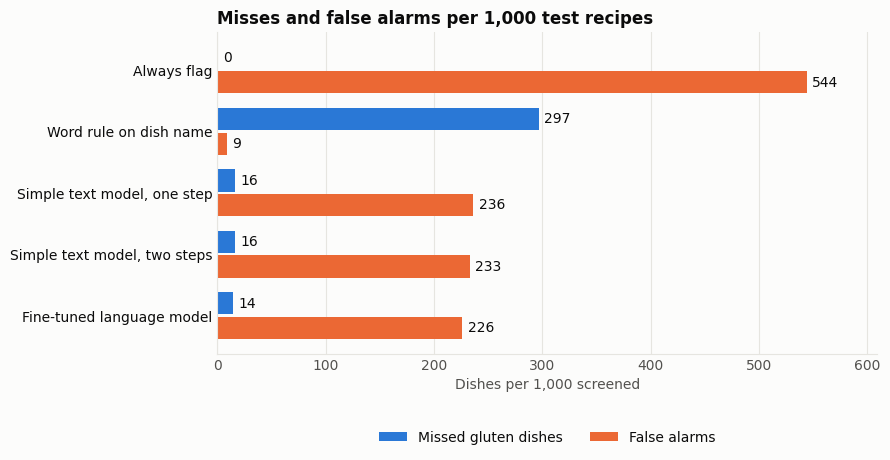

In [11]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

fig, ax = plt.subplots(figsize=(9, 0.8 * len(recipe_results) + 0.8))
y = np.arange(len(recipe_results))[::-1]
h = 0.36
b1 = ax.barh(y + h / 2 + 0.02, recipe_results["Misses per 1,000"], height=h, color=BLUE, label="Missed gluten dishes")
b2 = ax.barh(y - h / 2 - 0.02, recipe_results["False alarms per 1,000"], height=h, color=ORANGE, label="False alarms")
ax.bar_label(b1, fmt="%.0f", padding=4, color=INK)
ax.bar_label(b2, fmt="%.0f", padding=4, color=INK)
ax.set_yticks(y)
ax.set_yticklabels(recipe_results["Approach"], color=INK)
ax.set_xlabel("Dishes per 1,000 screened")
ax.set_xlim(0, recipe_results[["Misses per 1,000", "False alarms per 1,000"]].values.max() * 1.12)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(length=0)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
ax.set_title("Misses and false alarms per 1,000 test recipes", loc="left", fontweight="bold")
plt.tight_layout()
plt.savefig("chart1_recipes.png", dpi=200)
plt.show()

## Step 11. Nine restaurants' official allergen guides

EatThis will score restaurant menus, but the model learned from home recipes. Nine chains publish allergen guides that mark every item containing **wheat**. We extracted each guide's table, leaving out items marked only "may contain".

| Restaurant | Guide used (file as downloaded) | Edition |
| --- | --- | --- |
| Tatte | allergen-and-nutritional-guide-fall-v-091826-web.pdf | Fall 2026, updated 18 Sep 2026 |
| Panera Bread | c10-26-allergen-guide.pdf | Dated 4 Nov 2026 |
| Boudin Bakery | Master-Allergen-List_Q4-2026-Cheesesteaks_082726.pdf | Q4 2026, dated 27 Aug 2026 |
| Pret A Manger (US) | Allergen_Guide_September_2026.pdf | September 2026 |
| Cosi | Allergen_and_Nutritionals_Feb_2026.pdf | Stated current as of June 2026 |
| CAVA | KT6_26_AN_ANGUIDE_RETAIL_T_MKTAN11724.pdf | Undated, 2026 menu |
| Au Bon Pain | au-bon-pain-nutrition-fall-2018.pdf | Menu dated 6 Oct 2017 |
| Sweetgreen | sweetgreen.pdf | Undated seasonal menu; only 26 clearly legible items used |
| Chipotle (UK) | Combine-list-022025-UK.pdf | February 2025; lists ingredients, not dishes |


**Wheat is not gluten.** See the note at the top of this notebook.

### Which items count as a dish

The guides list everything a kitchen stocks, so each item was given one type by reading its name and the guide's headings. No model score was used.

- **Dish:** a prepared item a diner orders to eat on its own. This includes meals, sandwiches, salads, soups, single pastries and baked goods (a croissant, a cookie, a bagel) and sides eaten on their own (fries, a fruit cup). **Dishes are what we analyse.**
- **Component:** dressings, sauces, spreads, condiments, toppings, add-ons, proteins chosen for a build-your-own bowl, plain bread and loaves, and packaged snacks. Chipotle's guide lists only ingredients, so all of it falls here.
- **Drink.**
- **Catering or retail pack:** platters, boxes, trays and gift items.

The list was also cleaned: section headings and stray text that the extraction had picked up as items were removed, a few names that wrapped over two lines in a guide were repaired, and sizes of the same dish (small, medium, large; cup, bowl; whole, half) were merged into one. If any size is marked as containing wheat, the dish is counted as containing wheat. Every change is recorded in `restaurant_item_changes.csv` in the repository.

Each model then scores every item from its name alone, with its cut-off from Step 10. No restaurant item was used in training.

**How to read the result:** the number of items of each type at each restaurant.

In [12]:
RESTAURANT_ITEMS = [
    # (restaurant, item name, contains wheat per the guide: 1 yes, 0 no, item type)
    ('Boudin', 'BLTA', 1, 'dish'),
    ('Boudin', 'California Veggie', 1, 'dish'),
    ('Boudin', 'Caprese (Vegetarian)', 1, 'dish'),
    ('Boudin', 'Catalan (Vegan)', 1, 'dish'),
    ('Boudin', 'Catalan (Vegetarian)', 1, 'dish'),
    ('Boudin', 'Chicken Salad', 1, 'dish'),
    ('Boudin', 'Crispy Chicken Caesar Wrap', 1, 'dish'),
    ('Boudin', 'Crispy Chicken Parm', 1, 'dish'),
    ('Boudin', 'Deluxe French Dip', 1, 'dish'),
    ('Boudin', 'Grilled Brie with Apples & Fig Jam', 1, 'dish'),
    ('Boudin', 'Hot Chicken Pesto Sandwich', 1, 'dish'),
    ('Boudin', 'Italian Classic', 1, 'dish'),
    ('Boudin', 'Prosciutto & Pestos Sandwich', 1, 'dish'),
    ('Boudin', 'Sourdough French Dip', 1, 'dish'),
    ('Boudin', 'The Great Grilled Cheese', 1, 'dish'),
    ('Boudin', 'The Great with Bacon', 1, 'dish'),
    ('Boudin', 'Toasted Chicken Club', 1, 'dish'),
    ('Boudin', 'Tuna Salad', 1, 'dish'),
    ('Boudin', 'Tuna Melt', 1, 'dish'),
    ('Boudin', 'Turkey and Havarti', 1, 'dish'),
    ('Boudin', 'Turkey Avocado', 1, 'dish'),
    ('Boudin', 'Turkey Cranberry', 1, 'dish'),
    ('Boudin', 'The Classic Ribeye Cheesesteak', 1, 'dish'),
    ('Boudin', 'The Bold Ribeye Cheesesteak', 1, 'dish'),
    ('Boudin', 'Rustic Stuffing Turkey Cranberry', 1, 'dish'),
    ('Boudin', 'Thanksgiving Turkey Melt on Rustic Stuffing Bread', 1, 'dish'),
    ('Boudin', 'Asian Citrus Chicken Salad', 1, 'dish'),
    ('Boudin', 'Chicken, Apple, Walnut Salad', 0, 'dish'),
    ('Boudin', 'Crispy Chicken Avo Salad', 1, 'dish'),
    ('Boudin', 'Little Gem Cobb Salad', 1, 'dish'),
    ('Boudin', 'Mixed Greens (Side Salad)', 1, 'dish'),
    ('Boudin', 'Mixed Greens (Side Salad, No Croutons)', 0, 'dish'),
    ('Boudin', 'Traditional Caesar Salad', 1, 'dish'),
    ('Boudin', 'Add On Grilled All-Natural Chicken Breast', 0, 'component'),
    ('Boudin', 'Add On Crispy Fried Chicken Breast', 1, 'component'),
    ('Boudin', 'Green Goddess Chicken With Avocado Protein Bowl', 0, 'dish'),
    ('Boudin', 'Harvest Chicken Protein Bowl', 0, 'dish'),
    ('Boudin', 'Mediterranean Chicken W/ Lemon Hummus Protein Bowl', 0, 'dish'),
    ('Boudin', 'Broccoli Cheddar', 0, 'dish'),
    ('Boudin', 'Butternut Squash', 0, 'dish'),
    ('Boudin', 'Chili', 0, 'dish'),
    ('Boudin', 'Clam Chowder', 0, 'dish'),
    ('Boudin', 'Rustic Tomato', 1, 'dish'),
    ('Boudin', 'Cheese Pizza', 1, 'dish'),
    ('Boudin', 'Chicken Fingers & French Fries', 1, 'dish'),
    ('Boudin', 'Grilled Cheese', 1, 'dish'),
    ('Boudin', 'Mac & Cheese', 1, 'dish'),
    ('Boudin', 'Turkey Sandwich', 1, 'dish'),
    ('Boudin', 'All Meat', 1, 'dish'),
    ('Boudin', 'Cheesy Garlic Bread', 1, 'dish'),
    ('Boudin', 'Classic Pepperoni', 1, 'dish'),
    ('Boudin', 'Crowd Pleaser (50/50)', 1, 'dish'),
    ('Boudin', 'Four Cheese', 1, 'dish'),
    ('Boudin', 'Hawaiian Pizza', 1, 'dish'),
    ('Boudin', "Papa Steve's Original Style Pizza Bread", 1, 'dish'),
    ('Boudin', 'Sausage & Pepperoni', 1, 'dish'),
    ('Boudin', 'Four Cheese Pinsa Romana', 1, 'dish'),
    ('Boudin', 'Pepperoni Pinsa Romana', 1, 'dish'),
    ('Boudin', 'Prosciutto Bianca Pinsa Romana', 1, 'dish'),
    ('Boudin', 'Sausage & Pepperoni Hot Honey Pinsa Romana', 1, 'dish'),
    ('Boudin', 'Cookies & Cream', 1, 'drink'),
    ('Boudin', 'Dark Chocolate', 0, 'drink'),
    ('Boudin', 'Sea Salt Caramel', 0, 'drink'),
    ('Boudin', 'Strawberry', 0, 'drink'),
    ('Boudin', '*Seasonal* - Pumpkin Spice', 0, 'drink'),
    ('Boudin', 'Asiago Cheese', 1, 'component'),
    ('Boudin', 'Brioche (Buns & Rolls)', 1, 'component'),
    ('Boudin', 'Cinnamon Raisin', 1, 'component'),
    ('Boudin', 'Corn Rye', 1, 'component'),
    ('Boudin', 'English Muffins', 1, 'component'),
    ('Boudin', 'Pinsa Crust - 4 Pack', 1, 'catering or retail pack'),
    ('Boudin', 'Schiacciata Flatbread', 1, 'component'),
    ('Boudin', 'Sourdough (Loaves, Rolls, Baguettes, Lunch Boxes, Critters & Seasonal Shapes)', 1, 'component'),
    ('Boudin', 'Sweet Cinnamon Delight', 1, 'component'),
    ('Boudin', 'Multigrain (Loaves & Lunch Boxes)', 1, 'component'),
    ('Boudin', 'House Fries', 0, 'dish'),
    ('Boudin', 'Spicy Buttermilk Ranch Fries', 0, 'dish'),
    ('Boudin', 'Balsamic Dressing', 0, 'component'),
    ('Boudin', 'Basil Pesto Sauce', 0, 'component'),
    ('Boudin', 'Caesar Dressing', 0, 'component'),
    ('Boudin', 'Calabrian Chili Hot Honey', 0, 'component'),
    ('Boudin', 'Citrus, Garlic, & Herb Caesar Dressing', 0, 'component'),
    ('Boudin', 'Dijon Mustard', 0, 'component'),
    ('Boudin', 'Garlic Aioli Spread', 0, 'component'),
    ('Boudin', 'Honey Mustard', 0, 'component'),
    ('Boudin', 'Horseradish Mayo', 0, 'component'),
    ('Boudin', 'Lemon Hummus Dressing', 0, 'component'),
    ('Boudin', 'Lemon Vinaigrette Dressing', 0, 'component'),
    ('Boudin', 'Mayo', 0, 'component'),
    ('Boudin', 'Pesto Balsamic Dressing', 0, 'component'),
    ('Boudin', 'Pesto Mayo', 0, 'component'),
    ('Boudin', 'Ranch Dressing', 0, 'component'),
    ('Boudin', 'Romesco Sauce', 0, 'component'),
    ('Boudin', 'Spicy Asian Dressing', 1, 'component'),
    ('Boudin', 'Spicy Crema', 0, 'component'),
    ('Boudin', 'Sundried Tomato Spread', 0, 'component'),
    ('Boudin', 'Bacon & Cheddar on English Muffin', 1, 'dish'),
    ('Boudin', 'Cali-Style Bacon Breakfast Burrito', 1, 'dish'),
    ('Boudin', 'Cali-Style Veggie Breakfast Burrito', 1, 'dish'),
    ('Boudin', 'Granola & Greek Yogurt Parfait', 0, 'dish'),
    ('Boudin', 'Ham & Swiss on Croissant', 1, 'dish'),
    ('Boudin', 'Bacon', 0, 'component'),
    ('Boudin', 'Fruit Cup', 0, 'dish'),
    ('Boudin', 'Sourdough Toast', 1, 'component'),
    ('Boudin', 'English Muffin', 1, 'component'),
    ('Boudin', 'Multigrain Toast', 1, 'component'),
    ('Boudin', 'Traditional Deli Feast', 1, 'catering or retail pack'),
    ('Boudin', 'Ultimate Deli Feast', 1, 'catering or retail pack'),
    ('Boudin', 'Duo Salad', 1, 'catering or retail pack'),
    ('Boudin', 'Sausage Frittata Tray', 0, 'catering or retail pack'),
    ('Boudin', 'Vegetarian Frittata Tray', 0, 'catering or retail pack'),
    ('Boudin', 'Vegetarian Frittata Breakfast Sandwich', 1, 'catering or retail pack'),
    ('Boudin', 'Vegan Breakfast Burrito', 1, 'catering or retail pack'),
    ('Boudin', 'Ham & Swiss Breakfast Sandwich on English Muffin', 1, 'catering or retail pack'),
    ('Boudin', 'Egg & Cheddar Breakfast Sandwich on English Muffin', 1, 'catering or retail pack'),
    ('Boudin', 'Chicken & Waffle Breakfast Sandwich', 1, 'catering or retail pack'),
    ('Boudin', 'Oatmeal (Includes condiments)', 0, 'catering or retail pack'),
    ('Boudin', 'Simple Seasoned Eggs', 0, 'catering or retail pack'),
    ('Boudin', 'Avocado Toast Tray', 1, 'catering or retail pack'),
    ('Boudin', 'Bagel - Blueberry', 1, 'dish'),
    ('Boudin', 'Bagel - Cinnamon Raisin', 1, 'dish'),
    ('Boudin', 'Bagel - Onion', 1, 'dish'),
    ('Boudin', 'Bagel - Plain', 1, 'dish'),
    ('Boudin', 'Bagel - Sesame', 1, 'dish'),
    ('Boudin', 'Bar - Cookies & Cream', 1, 'dish'),
    ('Boudin', 'Bar - Double Fudge Brownie', 1, 'dish'),
    ('Boudin', 'Bar - "Gluten Friendly" Raspberry Almond Shortbread', 0, 'dish'),
    ('Boudin', 'Bar - Peanut Butter Crunch', 1, 'dish'),
    ('Boudin', 'Bar - Salted Caramel Pretzel Brownie', 1, 'dish'),
    ('Boudin', 'Chocolate Chip Banana Bread - Loaf & Mini', 1, 'dish'),
    ('Boudin', 'Cookie - Oatmeal Raisin Spice', 1, 'dish'),
    ('Boudin', 'Cookie - Peanut Butter', 1, 'dish'),
    ('Boudin', 'Cookie - Semi-Sweet Chocolate Chip', 1, 'dish'),
    ('Boudin', 'Cookie - Snickerdoodle', 1, 'dish'),
    ('Boudin', 'Cookie - The Royale', 0, 'dish'),
    ('Boudin', 'Cookie - White Chocolate Macadamia Nut', 1, 'dish'),
    ('Boudin', 'Croissant - Almond Lg. & Mini (NorCal & SoCal)', 1, 'dish'),
    ('Boudin', 'Croissant - Butter Lg. & Mini (NorCal & SoCal)', 1, 'dish'),
    ('Boudin', 'Croissant - Chocolate Lg. & Mini (NorCal & SoCal)', 1, 'dish'),
    ('Boudin', 'Loaf - Banana Pecan', 1, 'dish'),
    ('Boudin', 'Loaf - Marble Chocolate Chip', 1, 'dish'),
    ('Boudin', 'Loaf - Seasonal Pumpkin Swirl', 1, 'dish'),
    ('Boudin', 'Mini Coffee Cake', 1, 'dish'),
    ('Boudin', 'Morning Bun Lg. & Mini', 1, 'dish'),
    ('Boudin', 'Muffin - Banana Walnut', 1, 'dish'),
    ('Boudin', 'Muffin - Blueberry', 1, 'dish'),
    ('Boudin', 'Muffin - Iced Lemon Poppyseed', 1, 'dish'),
    ('Boudin', 'Scone - Artisan Blueberry', 1, 'dish'),
    ('Boudin', 'Scone - Artisan Cinnamon', 1, 'dish'),
    ('Boudin', 'Fruits & Cheese Tray', 1, 'catering or retail pack'),
    ('Boudin', 'California Vegetable Tray', 0, 'catering or retail pack'),
    ('Boudin', 'Antipasti', 1, 'dish'),
    ('Boudin', 'Ham & Swiss', 1, 'catering or retail pack'),
    ('Boudin', 'Pesto Roast Beef', 1, 'catering or retail pack'),
    ('Boudin', 'Roast Beef & Cheddar', 1, 'catering or retail pack'),
    ('Boudin', 'Catering Pesto Chicken', 1, 'catering or retail pack'),
    ('Boudin', '*Sandwiches Prepared on Gluten Free Bread', 0, 'catering or retail pack'),
    ('Boudin', 'Mini California Veggie', 1, 'catering or retail pack'),
    ('Boudin', 'Mini Chicken Salad', 1, 'catering or retail pack'),
    ('Boudin', 'Mini Ham & Swiss', 1, 'catering or retail pack'),
    ('Boudin', 'Mini Italiano', 1, 'catering or retail pack'),
    ('Boudin', 'Mini Roast Beef & Cheddar', 1, 'catering or retail pack'),
    ('Boudin', 'Mini Turkey Havarti', 1, 'catering or retail pack'),
    ('Cosi', 'Bowl, Adobo Chicken with Avocado', 0, 'dish'),
    ('Cosi', 'Bowl, Spicy Meatless Chorizo', 1, 'dish'),
    ('Cosi', 'Bowl, Shanghai Chicken', 1, 'dish'),
    ('Cosi', 'Bowl, Falafel & Harissa Hummus', 1, 'dish'),
    ('Cosi', 'Orange Juice, Large', 0, 'drink'),
    ('Cosi', 'Hard Boiled Eggs', 0, 'dish'),
    ('Cosi', 'Fruit Cup', 0, 'dish'),
    ('Cosi', 'Bagel, Asiago (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Jalepeno (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Multi-Grain (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Plain (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Cinnamon Raisin (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Seasame (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Everything (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Poppy (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bread Slice, Original* (Corporate)', 1, 'component'),
    ('Cosi', 'Bread Slice, Multi Grain* (Corporate)', 1, 'component'),
    ('Cosi', 'Bread Slice, Original* (Franchisee)', 1, 'component'),
    ('Cosi', 'Bread Slice, Multi Grain* (Franchisee)', 1, 'component'),
    ('Cosi', 'Croissant, Butter*', 1, 'dish'),
    ('Cosi', 'Crumb Cake, Butter*', 1, 'dish'),
    ('Cosi', 'Loaf, Lemon Pound Cake*', 1, 'dish'),
    ('Cosi', 'Loaf, Marble Pound Cake*', 1, 'dish'),
    ('Cosi', 'Muffin, Blueberry', 1, 'dish'),
    ('Cosi', 'Muffin, Lemon Cranberry', 1, 'dish'),
    ('Cosi', 'Muffin, Double Chocolate Chip', 1, 'dish'),
    ('Cosi', 'Muffin, Apple Cinnamon', 1, 'dish'),
    ('Cosi', 'Scone, Blueberry*', 1, 'dish'),
    ('Cosi', 'Scone, Orange Cranberry*', 1, 'dish'),
    ('Cosi', 'Cream Cheese, Low-fat', 0, 'component'),
    ('Cosi', 'Cream Cheese, Plain', 0, 'component'),
    ('Cosi', 'Cream Cheese, Veggie', 0, 'component'),
    ('Cosi', 'Brownie Bites, Blondie', 1, 'dish'),
    ('Cosi', 'Brownie Bites, Chocolate Chunk*', 1, 'dish'),
    ('Cosi', 'Brownie, Blondie*', 1, 'dish'),
    ('Cosi', 'Brownie, Chocolate Chunk*', 1, 'dish'),
    ('Cosi', 'Cookie, Chocolate Chip*', 1, 'dish'),
    ('Cosi', 'Blueberry Smash Lemonade', 0, 'drink'),
    ('Cosi', 'Iced Tea', 0, 'drink'),
    ('Cosi', 'Iced Tea, Raspberry', 0, 'drink'),
    ('Cosi', 'Lemonade', 0, 'drink'),
    ('Cosi', 'Mojito Lemonade', 0, 'drink'),
    ('Cosi', 'Café Americano', 0, 'drink'),
    ('Cosi', 'Cappuccino', 0, 'drink'),
    ('Cosi', 'Caramel Latte', 0, 'drink'),
    ('Cosi', 'Chai Tea Latte', 0, 'drink'),
    ('Cosi', 'Coffee', 0, 'drink'),
    ('Cosi', 'Espresso', 0, 'drink'),
    ('Cosi', 'Hot Chocolate', 0, 'drink'),
    ('Cosi', 'Latte', 0, 'drink'),
    ('Cosi', 'Mocha', 0, 'drink'),
    ('Cosi', 'Shot in the Dark', 0, 'drink'),
    ('Cosi', 'White Hot Chocolate', 0, 'drink'),
    ('Cosi', 'Cheese', 1, 'dish'),
    ('Cosi', 'Margherita Chicken', 1, 'dish'),
    ('Cosi', 'Margherita', 1, 'dish'),
    ('Cosi', 'Pepperoni', 1, 'dish'),
    ('Cosi', 'Kids Flatbread Cheese Pizza', 1, 'dish'),
    ('Cosi', 'Kids Flatbread Pepperoni Pizza', 1, 'dish'),
    ('Cosi', 'Kids Grape Cup', 0, 'dish'),
    ('Cosi', 'Kids Grilled Cheese', 1, 'dish'),
    ('Cosi', 'Kids Ham & Cheese', 1, 'dish'),
    ('Cosi', 'Kids Mac & Cheese', 1, 'dish'),
    ('Cosi', 'Kids Peanut Butter & Jelly', 1, 'dish'),
    ('Cosi', 'Kids Turkey Sandwich', 1, 'dish'),
    ('Cosi', 'Roasted Chicken', 0, 'component'),
    ('Cosi', 'Turkey', 0, 'component'),
    ('Cosi', 'Tofu', 0, 'component'),
    ('Cosi', 'Tuna Salad', 0, 'component'),
    ('Cosi', 'Southwest Adobo Chicken', 0, 'dish'),
    ('Cosi', 'Caesar', 1, 'dish'),
    ('Cosi', 'Caesar - Chicken', 1, 'dish'),
    ('Cosi', 'Cobb', 0, 'dish'),
    ('Cosi', 'Mediterranean Salad', 0, 'dish'),
    ('Cosi', 'Mandarin Chicken', 1, 'dish'),
    ('Cosi', 'Signature', 0, 'dish'),
    ('Cosi', 'Salad Dressing (Portion Only)', 0, 'component'),
    ('Cosi', 'Dressing - Adobo Vinaigrette', 0, 'component'),
    ('Cosi', 'Dressing - Caesar', 0, 'component'),
    ('Cosi', 'Dressing - Ginger Sesame', 1, 'component'),
    ('Cosi', 'Dressing - Cosi® Vinaigrette (Balsamic Vinaigrette)', 0, 'component'),
    ('Cosi', 'Dressing - Green Goddess', 0, 'component'),
    ('Cosi', 'Dressing - Sherry Shallot', 0, 'component'),
    ('Cosi', 'Bacon Turkey Cheddar', 1, 'dish'),
    ('Cosi', 'Pesto Chicken Melt', 1, 'dish'),
    ('Cosi', 'Fiery Chipotle Chicken Melt', 1, 'dish'),
    ('Cosi', 'Buffalo Chicken', 1, 'dish'),
    ('Cosi', 'Old World Italiano', 1, 'dish'),
    ('Cosi', 'Chicken Noodle', 1, 'dish'),
    ('Cosi', 'Fire Roasted Vegetable', 0, 'dish'),
    ('Cosi', 'French Onion Soup', 1, 'dish'),
    ('Cosi', 'Italian Wedding Soup', 1, 'dish'),
    ('Cosi', 'Macaroni & Cheese', 1, 'dish'),
    ('Cosi', 'Mediterranean Lentil', 0, 'dish'),
    ('Cosi', 'New England Clam Chowder', 0, 'dish'),
    ('Cosi', 'Turkey Chili', 1, 'dish'),
    ('Cosi', 'Tomato Basil', 0, 'dish'),
    ('Cosi', 'Chicken & Dumpling', 1, 'dish'),
    ('Panera', 'Asiago Cheese', 1, 'dish'),
    ('Panera', 'Asiago Everything', 1, 'dish'),
    ('Panera', 'Blueberry', 1, 'dish'),
    ('Panera', 'Chocolate Chip', 1, 'dish'),
    ('Panera', 'Cinnamon Crunch', 1, 'dish'),
    ('Panera', 'Cinnamon Swirl & Raisin', 1, 'dish'),
    ('Panera', 'Everything', 1, 'dish'),
    ('Panera', 'Multigrain Bagel Flat', 1, 'dish'),
    ('Panera', 'Plain', 1, 'dish'),
    ('Panera', 'Sesame', 1, 'dish'),
    ('Panera', 'Plain Cream Cheese Spread', 0, 'component'),
    ('Panera', 'Honey Walnut Cream Cheese Spread', 0, 'component'),
    ('Panera', 'Honey Pecan Cream Cheese Spread', 0, 'component'),
    ('Panera', 'Artisan Ciabatta- Loaf', 1, 'component'),
    ('Panera', 'Black Pepper Focaccia - Round Loaf', 1, 'component'),
    ('Panera', 'Classic White - Loaf', 1, 'component'),
    ('Panera', 'Country Rustic Sourdough - XL Loaf', 1, 'component'),
    ('Panera', 'Croissant', 1, 'dish'),
    ('Panera', 'French Baguette', 1, 'component'),
    ('Panera', 'Sourdough Bread Bowl', 1, 'component'),
    ('Panera', 'Tomato Basil - Miche', 1, 'component'),
    ('Panera', 'Whole Grain Lahvash Wrap', 1, 'component'),
    ('Panera', 'Italian Stuffer Roll - Retail whole', 1, 'component'),
    ('Panera', 'Brownie', 1, 'dish'),
    ('Panera', 'Cookie- Candy', 1, 'dish'),
    ('Panera', 'Cookie- Chocolate Chipper (Large & Petites)', 1, 'dish'),
    ('Panera', 'Cookie - Chocolate Coconut Macaroon', 1, 'dish'),
    ('Panera', 'Cookie - Coconut Macaroon', 1, 'dish'),
    ('Panera', 'Cookie - Dubai Style Chocolate Pistachio', 1, 'dish'),
    ('Panera', 'Cookie- Iced Shaped Shortbread- Pumpkin & Mitten', 1, 'dish'),
    ('Panera', 'Cookie- Kitchen Sink', 1, 'dish'),
    ('Panera', 'Cookie- Oatmeal Raisin with Berries', 1, 'dish'),
    ('Panera', 'Pastry - Cranberry Orange Loaf Slice - Naturally Flavored', 1, 'dish'),
    ('Panera', 'Muffin- Blueberry', 1, 'dish'),
    ('Panera', 'Muffie- Chocolate Chip', 1, 'dish'),
    ('Panera', 'Pastry - Almond', 1, 'dish'),
    ('Panera', 'Pastry - Asiago Croissant Twists', 1, 'dish'),
    ('Panera', 'Pastry - Cherry', 1, 'dish'),
    ('Panera', 'Pastry- Chocolate Croissant', 1, 'dish'),
    ('Panera', 'Pastry- Cinnamon Roll', 1, 'dish'),
    ('Panera', 'Pastry - Pumpkin Spice Cinnamon Roll', 1, 'dish'),
    ('Panera', 'Pastry- Pecan Braid', 1, 'dish'),
    ('Panera', 'Scone- Orange (Large & Mini)', 1, 'dish'),
    ('Panera', 'Cookie - PB & J', 1, 'dish'),
    ('Panera', 'Pastry - Cinnamon Croissant Bites with White Icing', 1, 'dish'),
    ('Panera', 'Add on - White Icing Portion Cup', 0, 'component'),
    ('Panera', 'Pastry - Cocoa Marshmallow Flavored Cake Slice', 1, 'dish'),
    ('Panera', 'Asiago Everything Bagel Stack - Wake-up BLT', 1, 'dish'),
    ('Panera', 'Asiago Bagel Stack - Farmhouse Duo', 1, 'dish'),
    ('Panera', 'Bacon, Egg & Cheese on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Bacon, Egg & Cheese on Croissant', 1, 'dish'),
    ('Panera', 'Bacon Double Take on Black Pepper Focaccia', 1, 'dish'),
    ('Panera', 'Chipotle Chicken, Egg & Avo on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Egg & Cheese on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Egg & Cheese on Croissant', 1, 'dish'),
    ('Panera', 'Egg Styles - Scrambled Egg or Egg White', 0, 'component'),
    ('Panera', 'Garden Avo & Egg White on Multigrain Bagel Flat', 1, 'dish'),
    ('Panera', 'Ham Croissant Benny', 1, 'dish'),
    ('Panera', 'Ham, Egg & Cheese on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Sausage, Egg & Cheese on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Sausage, Egg & Cheese on Croissant', 1, 'dish'),
    ('Panera', 'Steak & Wake on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Four Cheese Souffle', 1, 'dish'),
    ('Panera', 'Spinach & Bacon Souffle', 1, 'dish'),
    ('Panera', 'Fruit Cup', 0, 'dish'),
    ('Panera', 'Hard Boiled Eggs', 0, 'dish'),
    ('Panera', 'Parfait- Greek Yogurt with Berries', 0, 'dish'),
    ('Panera', 'Steel Cut Oatmeal with Strawberries & Pecans', 0, 'dish'),
    ('Panera', 'Steel Cut Oatmeal with Strawberries - Without Pecans', 0, 'dish'),
    ('Panera', 'Asian Sesame with & without Chicken', 1, 'dish'),
    ('Panera', 'Stuffer - Asian Sesame with & without Chicken', 1, 'dish'),
    ('Panera', 'Asian Sesame with & without Chicken - Without Almonds', 1, 'dish'),
    ('Panera', 'Stuffer - Asian Sesame with & without Chicken - without Almonds', 1, 'dish'),
    ('Panera', 'Caesar with & without Chicken', 1, 'dish'),
    ('Panera', 'Stuffer - Caesar with & without Chicken', 1, 'dish'),
    ('Panera', 'Stuffer - Farmhouse Crunch', 1, 'dish'),
    ('Panera', 'Farmhouse Crunch Salad - without almonds', 0, 'dish'),
    ('Panera', 'Stuffer - Farmhouse Crunch - without almonds', 1, 'dish'),
    ('Panera', 'Fuji Apple with & without Chicken', 0, 'dish'),
    ('Panera', 'Stuffer - Fuji Apple with & without Chicken', 1, 'dish'),
    ('Panera', 'Fuji Apple with & without Chicken - Without Pecans', 0, 'dish'),
    ('Panera', 'Stuffer - Fuji Apple with & without Chicken - without Pecans', 1, 'dish'),
    ('Panera', 'Greek with & without Chicken', 0, 'dish'),
    ('Panera', 'Stuffer - Greek with & without Chicken', 1, 'dish'),
    ('Panera', 'Green Goddess Cobb with Chicken', 0, 'dish'),
    ('Panera', 'Stuffer - Green Goddess Cobb with Chicken', 1, 'dish'),
    ('Panera', 'Ranch Parm BLT', 1, 'dish'),
    ('Panera', 'Stuffer - Ranch Parm BLT', 1, 'dish'),
    ('Panera', 'Southwest Chicken Ranch', 0, 'dish'),
    ('Panera', 'Stuffer - Southwest Chicken Ranch', 1, 'dish'),
    ('Panera', 'Ultimate Garden Steak Salad', 1, 'dish'),
    ('Panera', 'Stuffer - Ultimate Garden Steak', 1, 'dish'),
    ('Panera', 'Harvest Medley with and without Chicken', 1, 'dish'),
    ('Panera', 'Stuffer- Harvest Medley with and without Chicken', 1, 'dish'),
    ('Panera', 'Harvest Medley with and without Chicken - No Pecans', 1, 'dish'),
    ('Panera', 'Stuffer- Harvest Medley with and without Chicken - No Pecans', 1, 'dish'),
    ('Panera', 'All-In Veggie', 1, 'dish'),
    ('Panera', 'Sesame Ginger Chicken', 1, 'dish'),
    ('Panera', 'Sesame Ginger Chicken - No Almonds', 1, 'dish'),
    ('Panera', 'Carnitas Elote', 0, 'dish'),
    ('Panera', 'Asiago Bagel Stack - Spicy Steak', 1, 'dish'),
    ('Panera', 'Bacon Turkey Bravo on Tomato Basil', 1, 'dish'),
    ('Panera', 'Chicken Bacon Rancher on Black Pepper Focaccia', 1, 'dish'),
    ('Panera', 'Chipotle Chicken Avo Melt on Round Black Pepper Focaccia', 1, 'dish'),
    ('Panera', 'Ciabatta Cheesesteak', 1, 'dish'),
    ('Panera', 'Cranberry Walnut Chicken Salad on Country Rustic', 1, 'dish'),
    ('Panera', 'Grilled Cheese on Classic White Loaf', 1, 'dish'),
    ('Panera', 'Grilled Chicken & Avo BLT on Country Rustic Sourdough', 1, 'dish'),
    ('Panera', 'Mediterranean Veggie on Tomato Basil', 1, 'dish'),
    ('Panera', 'Pickle Spear for cold sandwiches', 0, 'component'),
    ('Panera', 'Smokehouse BBQ Chicken on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Toasted Frontega Chicken on Black Pepper Focaccia', 1, 'dish'),
    ('Panera', 'Toasted Italiano on Baguette', 1, 'dish'),
    ('Panera', 'Tomato Basil BLT on Tomato Basil Miche', 1, 'dish'),
    ('Panera', 'Toasted Caprese Focaccia', 1, 'dish'),
    ('Panera', 'Tuna Salad on Country Rustic Sourdough', 1, 'dish'),
    ('Panera', 'Turkey & Cheddar on Country Rustic Sourdough', 1, 'dish'),
    ('Panera', 'Spicy Fiesta Chicken on Ciabatta', 1, 'dish'),
    ('Panera', 'Catering- Ham & Cheddar on Country Rustic', 1, 'catering or retail pack'),
    ('Panera', 'Ciabatta Dipper - French', 1, 'dish'),
    ('Panera', 'Ciabatta Dipper - Chicken Pesto', 1, 'dish'),
    ('Panera', 'Dressing - Asian Sesame vinaigrette', 0, 'component'),
    ('Panera', 'Sauce - Balsamic Glaze', 0, 'component'),
    ('Panera', 'Sauce - Balsamic Vinaigrette', 0, 'component'),
    ('Panera', 'Sauce - Bravo Signature', 0, 'component'),
    ('Panera', 'Dressing - Caesar', 0, 'component'),
    ('Panera', 'Sauce - Cheese Hollandaise', 0, 'component'),
    ('Panera', 'Sauce - Chipotle Aioli', 0, 'component'),
    ('Panera', 'Dressing - Creamy Garden Herb', 0, 'component'),
    ('Panera', 'Sauce - Creamy Basil Pesto', 0, 'component'),
    ('Panera', 'Dressing - Farmhouse Ranch', 0, 'component'),
    ('Panera', 'Sauce - Garlic Aioli', 0, 'component'),
    ('Panera', 'Dressing - Greek', 0, 'component'),
    ('Panera', 'Sauce - Green Chile Salsa Verde', 0, 'component'),
    ('Panera', 'Dressing - Green Goddess', 0, 'component'),
    ('Panera', 'Spread- Hummus', 0, 'component'),
    ('Panera', 'Sauce - Mayonnaise', 0, 'component'),
    ('Panera', 'Dressing - Sesame Ginger', 1, 'component'),
    ('Panera', 'Dressing - White Balsamic Apple Flavored Vinaigrette', 0, 'component'),
    ('Panera', 'Dressing - Zesty Smoky Lemon Vinaigrette', 1, 'component'),
    ('Panera', 'Dipper - Creamy Tomato - Dipper Portion', 0, 'component'),
    ('Panera', 'Dipper - Bistro French Onion - Dipper Portion', 1, 'component'),
    ('Panera', 'Additional Pump of Caramel Syrup', 0, 'component'),
    ('Panera', 'Additional Pump of Chocolate Sauce', 0, 'component'),
    ('Panera', 'Additional Pump of Chocolatey Hazelnut Flavored Syrup', 0, 'component'),
    ('Panera', 'Additional Pump of Madagascar Vanilla Syrup or Cane Sugar Syrup', 0, 'component'),
    ('Panera', 'Additional Shot of Pumpkin Spice Sauce', 0, 'component'),
    ('Panera', 'Additional Pump of Snickerdoodle Syrup', 0, 'component'),
    ('Panera', 'Additional Pump of White Chocolate and Peppermint Flavored Sauce', 0, 'component'),
    ('Panera', 'Additional Pump of White Chocolate and Pistachio Flavored Sauce', 0, 'component'),
    ('Panera', 'Agave Lemonade', 0, 'drink'),
    ('Panera', 'Americano', 0, 'drink'),
    ('Panera', 'Blackberry Hibiscus Iced Tea - Naturally Flavored Herbal Tea', 0, 'drink'),
    ('Panera', 'Cafe Frozen Java', 0, 'drink'),
    ('Panera', 'Caffe Latte (espresso - Hot or Iced)', 0, 'drink'),
    ('Panera', 'Cappuccino (espresso)', 0, 'drink'),
    ('Panera', 'Caramel Latte (espresso - Hot or Iced)', 0, 'drink'),
    ('Panera', 'Chai Tea Latte (Hot or Iced)', 0, 'drink'),
    ('Panera', 'Cherry Lime Fresca', 0, 'drink'),
    ('Panera', 'Coffee/Decaf Coffee (Hot or Iced)', 0, 'drink'),
    ('Panera', 'Dragonfruit Sunset Energy Refresher - Naturally Flavored', 0, 'drink'),
    ('Panera', 'Hot Tea Bags', 0, 'drink'),
    ('Panera', 'Iced Teas - Unsweetened / Sweetened / Passion Papaya Naturally Flavored Green Tea', 0, 'drink'),
    ('Panera', 'Island Mango Energy Refresher - Naturally Flavored - With Dragon Fruit', 0, 'drink'),
    ('Panera', 'Island Mango Energy Refresher - Naturally Flavored - With Pineapple', 0, 'drink'),
    ('Panera', 'Madagascar Vanilla Latte (espresso - Hot or Iced)', 0, 'drink'),
    ('Panera', 'Mango Smoothie with Greek Yogurt (Frozen)', 0, 'drink'),
    ('Panera', 'Mocha Latte (espresso - Hot or Iced)', 0, 'drink'),
    ('Panera', 'Passionfruit Paradise Energy Refresher - Naturally Flavored', 0, 'drink'),
    ('Panera', 'Pumpkin Spice Frozen Java', 0, 'drink'),
    ('Panera', 'Pumpkin Spice Iced Coffee', 0, 'drink'),
    ('Panera', 'Pumpkin Spice Latte - (Hot or Iced)', 0, 'drink'),
    ('Panera', 'Pistachio White Mocha Frozen Java', 0, 'drink'),
    ('Panera', 'Pistachio White Mocha Latte', 0, 'drink'),
    ('Panera', 'Pistachio White Mocha Iced Latte', 0, 'drink'),
    ('Panera', 'Pistachio White Mocha Iced Coffee', 0, 'drink'),
    ('Panera', 'Signature Hot Chocolate - (Hot or Frozen)', 0, 'drink'),
    ('Panera', 'Strawberry Banana Smoothie with Greek Yogurt (Frozen)', 0, 'drink'),
    ('Panera', 'Strawberry Basil Lemonade Fresca', 0, 'drink'),
    ('Panera', 'Strawberry Smoothie with Greek Yogurt (Frozen)', 0, 'drink'),
    ('Panera', 'Sweet Cream Cold Foam', 0, 'component'),
    ('Panera', 'Tropical Green Smoothie (Frozen)', 0, 'drink'),
    ('Panera', 'Kids Broccoli Cheddar Soup', 1, 'dish'),
    ('Panera', 'Kids Ham & American Cheese on Classic White Loaf', 1, 'dish'),
    ('Panera', 'Kids Turkey & American Cheese on Classic White Loaf', 1, 'dish'),
    ('Panera', 'Mac & Cheese', 1, 'dish'),
    ('Panera', 'Bistro French Onion with Cheese & Croissant Croutons', 1, 'dish'),
    ('Panera', 'Broccoli Cheddar', 1, 'dish'),
    ('Panera', 'Cream of Chicken & Wild Rice', 1, 'dish'),
    ('Panera', 'Homestyle Chicken Noodle', 1, 'dish'),
    ('Panera', 'Creamy Tomato with Croissant Croutons - Vegetarian', 1, 'dish'),
    ('Panera', 'Bacon Mac & Cheese', 1, 'dish'),
    ('Panera', 'Rustic Baked Potato', 0, 'dish'),
    ('Panera', 'Three Cheese Lasagna', 1, 'dish'),
    ('Panera', 'Autumn Squash - Vegetarian', 0, 'dish'),
    ('Panera', 'Grab N Go Chicken Caesar Wrap', 1, 'dish'),
    ('Panera', 'Frontega Chicken Wrap', 1, 'dish'),
    ('Panera', 'Green Goddess Chicken Wrap', 1, 'dish'),
    ('Panera', 'Turkey & Cheddar Wrap', 1, 'dish'),
    ('Pret', 'Pesto Caprese Baguette', 1, 'dish'),
    ('Pret', "Pret's Chicken Bánh Mi", 1, 'dish'),
    ('Pret', 'Pret’s Famous Ham & Cheese Baguette', 1, 'dish'),
    ('Pret', "Pret's Tuna & Cucumber Baguette", 1, 'dish'),
    ('Pret', 'Romesco Chicken & Mozzarella Baguette', 1, 'dish'),
    ('Pret', 'Cheddar & Tomato Sandwich', 1, 'dish'),
    ('Pret', 'Chicken & Bacon Sandwich', 1, 'dish'),
    ('Pret', "Pret's Chicken Salad & Avo Sandwich", 1, 'dish'),
    ('Pret', "Pret's Egg Salad & Arugula Sandwich", 1, 'dish'),
    ('Pret', "Pret's Tuna & Cucumber Sandwich", 1, 'dish'),
    ('Pret', 'Rainbow Veggie Sandwich', 1, 'dish'),
    ('Pret', 'Turkey & Cheddar Sandwich', 1, 'dish'),
    ('Pret', "Kid's Ham & Cheddar Sandwich", 1, 'dish'),
    ('Pret', "Kid's Cheddar & Mayo Sandwich", 1, 'dish'),
    ('Pret', 'Avocado Veggie Sandwich', 1, 'dish'),
    ('Pret', 'Pret’s Italian Turkey Club Sandwich', 1, 'dish'),
    ('Pret', 'BBQ Pulled Pork Melt', 1, 'dish'),
    ('Pret', 'Buffalo Chicken Melt', 1, 'dish'),
    ('Pret', 'Roasted Mushroom & Swiss Melt', 1, 'dish'),
    ('Pret', 'Bang Bang Chicken Wrap', 1, 'dish'),
    ('Pret', 'Crunchy Chipotle Chicken & Avo Wrap', 1, 'dish'),
    ('Pret', 'Crunchy Miso Mushroom Wrap', 1, 'dish'),
    ('Pret', 'Falafel & Hummus Wrap', 1, 'dish'),
    ('Pret', 'Spicy Chicken Caesar Wrap', 1, 'dish'),
    ('Pret', 'Pret’s Chicken Parm Wrap', 1, 'dish'),
    ('Pret', "Pret's Pulled Pork Burrito", 1, 'dish'),
    ('Pret', 'Spiced Lentil & Chickpea Hot Wrap', 1, 'dish'),
    ('Pret', 'Chicken Burrito Wrap', 1, 'dish'),
    ('Pret', 'Ham & Cheddar Croissant', 1, 'dish'),
    ('Pret', 'Turkey & Swiss Croissant', 1, 'dish'),
    ('Pret', 'Broccoli Cheddar & Chive Quiche', 1, 'dish'),
    ('Pret', 'Spinach & Fontina Quiche', 1, 'dish'),
    ('Pret', 'Bread Roll', 1, 'component'),
    ('Pret', 'Chili Yogurt & Herbs Soup Topper', 1, 'component'),
    ('Pret', 'Croutons, Lemon & Herbs Soup Topper', 1, 'component'),
    ('Pret', 'Moroccan Lentil Soup', 0, 'dish'),
    ('Pret', 'Roasted Veggie Harvest Soup', 0, 'dish'),
    ('Pret', 'Super Greens Soup', 0, 'dish'),
    ('Pret', 'Tomato & Feta Soup', 0, 'dish'),
    ('Pret', 'Turmeric Chicken & Farro Soup', 1, 'dish'),
    ('Pret', 'White Chicken Chili', 0, 'dish'),
    ('Pret', 'Classic Mac and Cheese', 1, 'dish'),
    ('Pret', 'Spinach & Tomato Mac and Cheese', 1, 'dish'),
    ('Pret', 'Pumpkin Bisque', 0, 'dish'),
    ('Pret', "Blackened Salmon, Avo & Quinoa Salad with Pret's Simple", 0, 'dish'),
    ('Pret', 'Vinaigrette', 0, 'component'),
    ('Pret', 'Blackened Salmon, Avo & Quinoa Salad without Dressing', 0, 'dish'),
    ('Pret', "Chicken Avocado Salad with Pret's Simple Vinaigrette", 0, 'dish'),
    ('Pret', 'Chicken Avocado Salad without Dressing', 0, 'dish'),
    ('Pret', 'Chicken Caesar Salad with Caesar Dressing', 1, 'dish'),
    ('Pret', 'Chicken Caesar Salad without Dressing', 1, 'dish'),
    ('Pret', 'Chicken, Elote Corn & Avocado Salad with Herb Yogurt Dressing', 0, 'dish'),
    ('Pret', "Elote Chicken salad with Pret's Simple Vinaigrette (LAX)", 0, 'dish'),
    ('Pret', 'Chicken, Elote Corn & Avocado Salad without Dressing', 0, 'dish'),
    ('Pret', "Chicken & Strawberry Salad with Pret's Simple Vinaigrette", 0, 'dish'),
    ('Pret', 'Chicken & Strawberry Salad without Dressing', 0, 'dish'),
    ('Pret', "Mediterranean Mezze Salad with Pret's Simple Vinaigrette", 0, 'dish'),
    ('Pret', 'Mediterranean Mezze Salad without Dressing', 0, 'dish'),
    ('Pret', "Pesto Marinated White Bean & Avocado Salad with Pret's Simple", 0, 'dish'),
    ('Pret', 'Pesto Marinated White Bean & Avocado Salad without Dressing', 0, 'dish'),
    ('Pret', 'Caesar Side Salad with Caesar Dressing', 1, 'dish'),
    ('Pret', 'Caesar Side Salad without Dressing', 1, 'dish'),
    ('Pret', "Pret's Greek Side Salad with Herb Yogurt Dressing", 1, 'dish'),
    ('Pret', "Pret's Greek Side Salad without Dressing", 1, 'dish'),
    ('Pret', "Lemon Arugula Side Salad with Pret's Simple Vinaigrette", 0, 'dish'),
    ('Pret', 'Lemon Arugula Side Salad without Dressing', 0, 'dish'),
    ('Pret', 'Caesar Dressing', 1, 'component'),
    ('Pret', 'Herb Yogurt Dressing', 0, 'component'),
    ('Pret', "Pret's Simple Vinaigrette", 0, 'component'),
    ('Pret', 'Egg Salad & Avocado Breakfast Baguette', 1, 'dish'),
    ('Pret', 'Bacon, Egg & Cheddar Roll', 1, 'dish'),
    ('Pret', 'Egg & Cheddar Roll', 1, 'dish'),
    ('Pret', 'Southwestern Breakfast Wrap', 1, 'dish'),
    ('Pret', 'Southwestern Breakfast Wrap with bacon', 1, 'dish'),
    ('Pret', 'Apple Cranberry Crunch Porridge Topper', 0, 'component'),
    ('Pret', 'Coconut Banana Blueberry Porridge Topper', 0, 'component'),
    ('Pret', 'Oatm*lk Porridge', 0, 'dish'),
    ('Pret', 'Egg White Greek Frittata', 0, 'dish'),
    ('Pret', 'Power Breakfast Frittata', 0, 'dish'),
    ('Pret', 'Dragon Fruit Yogurt Protein Pot', 0, 'dish'),
    ('Pret', 'Sunset Smoothie Pot', 0, 'drink'),
    ('Pret', 'Egg Salad & Bacon Sourdough Breakfast Baguette', 1, 'dish'),
    ('Pret', 'Bacon, Egg & Cheddar Sourdough Breakfast Half Baguette', 1, 'dish'),
    ('Pret', 'Egg & Cheddar Sourdough Breakfast Half Baguette', 1, 'dish'),
    ('Pret', 'Roasted Tomato & Mozzarella Croissant', 1, 'dish'),
    ('Pret', 'Apple Cinnamon Oatm*lk Porridge', 1, 'dish'),
    ('Pret', 'Brown Sugar & Banana Oatm*lk Porridge', 1, 'dish'),
    ('Pret', 'Banana', 0, 'dish'),
    ('Pret', 'Cantaloupe & Blueberry Pot', 0, 'dish'),
    ('Pret', 'Pineapple & Lime Pot', 0, 'dish'),
    ('Pret', 'Strawberry & Blueberry Pot', 0, 'dish'),
    ('Pret', 'Banana & Honey Yogurt Pot (LAX Only)', 0, 'dish'),
    ('Pret', 'Berry Yogurt Parfait Pot (LAX ONLY)', 0, 'dish'),
    ('Pret', 'Bircher Muesli', 0, 'dish'),
    ('Pret', 'Blueberry & Granola Pot', 0, 'dish'),
    ('Pret', 'Blueberry Yogurt Pot', 0, 'dish'),
    ('Pret', 'Dragon Fruit Coconut Chia Bowl', 0, 'dish'),
    ('Pret', 'Egg & Spinach Pot', 0, 'dish'),
    ('Pret', 'Guava Coconut Chia Pot', 0, 'dish'),
    ('Pret', 'Hummus Pot', 0, 'dish'),
    ('Pret', 'Little Cup of Goodness', 0, 'dish'),
    ('Pret', 'Strawberry Yogurt Pot', 0, 'dish'),
    ('Pret', 'Chobani Strawberry Yogurt Protein Pot', 0, 'dish'),
    ('Pret', 'Sunshine Bowl', 0, 'dish'),
    ('Pret', "Kid's Honey Banana Yogurt Pot (NYC Only)", 0, 'dish'),
    ('Pret', 'Pumpkin Spice Yogurt Pot', 0, 'dish'),
    ('Pret', 'Almond Croissant', 1, 'dish'),
    ('Pret', 'Chocolate Croissant', 1, 'dish'),
    ('Pret', 'Plain Croissant', 1, 'dish'),
    ('Pret', 'Blueberry Muffin', 1, 'dish'),
    ('Pret', 'Cinnamon Kouign Amann ("queen a-mahn")', 1, 'dish'),
    ('Pret', 'Everything Cream Cheese Swirl', 1, 'dish'),
    ('Pret', 'Chocolate Chunk Cookie', 1, 'dish'),
    ('Pret', 'Chocolate Brownie Cookie', 1, 'dish'),
    ('Pret', 'Double Chocolate Pecan Cookie', 1, 'dish'),
    ('Pret', 'Harvest Cookie', 1, 'dish'),
    ('Pret', 'Pumpkin Cheese Danish', 1, 'dish'),
    ('Pret', 'Brownie Bite', 1, 'dish'),
    ('Pret', 'Key Lime Cheesecake', 1, 'dish'),
    ('Pret', 'Raspberry Cheesecake', 1, 'dish'),
    ('Pret', 'Tiramisu Cheesecake', 1, 'dish'),
    ('Pret', 'Chocolate Covered Almonds', 0, 'component'),
    ('Pret', 'Omega-3 Mix', 0, 'component'),
    ('Pret', 'Raw Almonds', 0, 'component'),
    ('Pret', 'Coffee', 0, 'drink'),
    ('Pret', 'Americano Black', 0, 'drink'),
    ('Pret', 'Cappuccino (Almond Milk)', 0, 'drink'),
    ('Pret', 'Cappuccino (Oat Milk)', 0, 'drink'),
    ('Pret', 'Cappuccino (Half and Half)', 0, 'drink'),
    ('Pret', 'Cappuccino (Skim Milk)', 0, 'drink'),
    ('Pret', 'Cappuccino (Whole Milk)', 0, 'drink'),
    ('Pret', 'Espresso', 0, 'drink'),
    ('Pret', 'Macchiato (Almond Milk)', 0, 'drink'),
    ('Pret', 'Macchiato (Oat Milk)', 0, 'drink'),
    ('Pret', 'Macchiato (Half and Half)', 0, 'drink'),
    ('Pret', 'Macchiato (Skim Milk)', 0, 'drink'),
    ('Pret', 'Macchiato (Whole Milk)', 0, 'drink'),
    ('Pret', 'Flat White (Almond Milk)', 0, 'drink'),
    ('Pret', 'Flat White (Oat Milk)', 0, 'drink'),
    ('Pret', 'Flat White (Half and Half)', 0, 'drink'),
    ('Pret', 'Flat White (Skim Milk)', 0, 'drink'),
    ('Pret', 'Flat White (Whole Milk)', 0, 'drink'),
    ('Pret', 'Coffee (Cont.)', 0, 'drink'),
    ('Pret', 'Mocha (Almond Milk)', 0, 'drink'),
    ('Pret', 'Mocha (Oat Milk)', 0, 'drink'),
    ('Pret', 'Mocha (Half & Half)', 0, 'drink'),
    ('Pret', 'Mocha (Skim Milk)', 0, 'drink'),
    ('Pret', 'Mocha (Whole Milk)', 0, 'drink'),
    ('Pret', 'Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Latte (Whole Milk)', 0, 'drink'),
    ('Pret', "Pret's Organic Single Origin Coffee Black", 0, 'drink'),
    ('Pret', "Pret's Organic Classic Blend Coffee Black", 0, 'drink'),
    ('Pret', 'Chai Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Chai Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Chai Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Chai Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Chai Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Matcha Chai Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Matcha Chai Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Matcha Chai Latte (Half & Half Milk)', 0, 'drink'),
    ('Pret', 'Matcha Chai Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Matcha Chai Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Matcha Latte (Almond milk)', 0, 'drink'),
    ('Pret', 'Matcha Latte (Oat milk)', 0, 'drink'),
    ('Pret', 'Matcha Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Matcha Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Matcha Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Hot Chocolate (Almond Milk)', 0, 'drink'),
    ('Pret', 'Hot Chocolate (Oat Milk)', 0, 'drink'),
    ('Pret', 'Hot Chocolate (Half & Half)', 0, 'drink'),
    ('Pret', 'Hot Chocolate (Skim Milk)', 0, 'drink'),
    ('Pret', 'Hot Chocolate (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Coffee', 0, 'drink'),
    ('Pret', 'Cold Brew (Black)', 0, 'drink'),
    ('Pret', 'Iced Americano (Black)', 0, 'drink'),
    ('Pret', 'Iced Coffee (Black)', 0, 'drink'),
    ('Pret', 'Iced Espresso (Black)', 0, 'drink'),
    ('Pret', 'Iced Mocha (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Mocha (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Mocha (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Mocha (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Mocha (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Chai Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Chai Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Chai Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Chai Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Chai Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Chocolate (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Chocolate (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Chocolate (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Chocolate (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Chocolate (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Matcha (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Matcha (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Matcha (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Matcha (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Matcha (Whole Milk)', 0, 'drink'),
    ('Pret', 'Pink Guava Matcha Iced Latte (Almond', 0, 'drink'),
    ('Pret', 'Pink Guava Matcha Iced Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Pink Guava Matcha Iced Latte (Half &Half)', 0, 'drink'),
    ('Pret', 'Pink Guava Matcha Iced Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Pink Guava Matcha Iced Latte (Whole', 0, 'drink'),
    ('Pret', 'Iced Teas, Lemonade and Refreshers', 0, 'drink'),
    ('Pret', 'Iced Black Tea', 0, 'drink'),
    ('Pret', 'Iced Green Tea', 0, 'drink'),
    ('Pret', 'Sunshine Black Tea', 0, 'drink'),
    ('Pret', 'Sunshine Green Tea', 0, 'drink'),
    ('Pret', 'Pink Guava Lemonade', 0, 'drink'),
    ('Pret', 'Pink Guava Sunshine Black Tea', 0, 'drink'),
    ('Pret', 'Pink Guava Sunshine Green Tea', 0, 'drink'),
    ('Pret', 'Pink Guava Black Tea', 0, 'drink'),
    ('Pret', 'Pink Guava Green Tea', 0, 'drink'),
    ('Pret', 'Dragon Fruit Mango Black Tea', 0, 'drink'),
    ('Pret', 'Dragon Fruit Mango Green Tea', 0, 'drink'),
    ('Pret', 'Dragon Fruit Mango Lemonade', 0, 'drink'),
    ('Pret', 'Dragon Fruit Mango Sunshine Black Tea', 0, 'drink'),
    ('Pret', 'Dragon Fruit Mango Sunshine Green Tea', 0, 'drink'),
    ('Pret', 'Lemonade', 0, 'drink'),
    ('Pret', 'Matcha Lemonade', 0, 'drink'),
    ('Pret', 'Cane Syrup', 0, 'component'),
    ('Pret', 'Caramel Syrup', 0, 'component'),
    ('Pret', 'Hazelnut Syrup', 0, 'component'),
    ('Pret', 'Vanilla Syrup', 0, 'component'),
    ('Pret', 'Classic Whipped Cream', 0, 'component'),
    ('Pret', 'Almond Milk', 0, 'drink'),
    ('Pret', 'Oat Milk', 0, 'drink'),
    ('Pret', 'Half & Half', 0, 'component'),
    ('Pret', 'Skim Milk', 0, 'drink'),
    ('Pret', 'Whole Milk', 0, 'drink'),
    ('Pret', 'Breakfast Tea', 0, 'drink'),
    ('Pret', 'Earl Grey Tea', 0, 'drink'),
    ('Pret', 'Peppermint Tea', 0, 'drink'),
    ('Pret', 'Tropical Green Tea', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Matcha Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Matcha Latte (Skim', 0, 'drink'),
    ('Pret', 'Ice Spiced Pumpkin Matcha Latte (Whole', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Matcha Latte', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Matcha Latte (Oat', 0, 'drink'),
    ('Pret', 'Ice Spiced Pumpkin Matcha Latte (Half &', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Matcha Latte (Whole', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Matcha Latte (Almond', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Matcha Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Pumpkin Spice Sauce', 0, 'component'),
    ('Pret', 'Daily Greens Cold Pressed Juice', 0, 'drink'),
    ('Pret', 'Super Reds Cold Pressed Juice', 0, 'drink'),
    ('Pret', 'Pink Grapefruit Juice', 0, 'drink'),
    ('Pret', 'Orange Juice', 0, 'drink'),
    ('Pret', 'Classic Lemonade', 0, 'drink'),
    ('Pret', 'Strawberry Lemonade', 0, 'drink'),
    ('CAVA', 'Greek Goddess Steak Salad', 0, 'dish'),
    ('CAVA', 'Greek Goddess Salmon Bowl', 0, 'dish'),
    ('CAVA', 'Spicy Lamb + Avocado Bowl', 0, 'dish'),
    ('CAVA', 'Steak + Harissa Bowl', 0, 'dish'),
    ('CAVA', 'Harissa Avocado Bowl', 0, 'dish'),
    ('CAVA', 'Chicken + Rice Bowl', 0, 'dish'),
    ('CAVA', 'Greek Salad Bowl', 0, 'dish'),
    ('CAVA', 'Falafel Crunch Bowl', 1, 'dish'),
    ('CAVA', 'Salmon + Yogurt Dill Bowl', 0, 'dish'),
    ('CAVA', 'Pomegranate Glazed Salmon Bowl', 0, 'dish'),
    ('CAVA', 'Spicy Chicken + Avocado Pita', 1, 'dish'),
    ('CAVA', 'Steak + Feta Pita', 1, 'dish'),
    ('CAVA', 'Greek Chicken Pita', 1, 'dish'),
    ('CAVA', 'Brown Rice', 0, 'component'),
    ('CAVA', 'Saffron Basmati Rice', 0, 'component'),
    ('CAVA', 'Black Lentils', 0, 'component'),
    ('CAVA', 'Super Greens', 0, 'component'),
    ('CAVA', 'Arugula', 0, 'component'),
    ('CAVA', 'Baby Spinach', 0, 'component'),
    ('CAVA', 'Romaine', 0, 'component'),
    ('CAVA', 'Power Greens', 0, 'component'),
    ('CAVA', 'Braised Lamb', 0, 'component'),
    ('CAVA', 'Grilled Chicken', 0, 'component'),
    ('CAVA', 'Falafel', 1, 'component'),
    ('CAVA', 'Grilled Steak', 0, 'component'),
    ('CAVA', 'Harissa Honey Chicken', 0, 'component'),
    ('CAVA', 'Roasted Vegetables', 0, 'component'),
    ('CAVA', 'Spicy Lamb Meatballs', 0, 'component'),
    ('CAVA', 'Glazed Salmon', 0, 'component'),
    ('CAVA', 'Kids Saffron Basmati Rice', 0, 'component'),
    ('CAVA', 'Kids Brown Rice', 0, 'component'),
    ('CAVA', 'Kids Black Lentils', 0, 'component'),
    ('CAVA', 'Kids Chicken', 0, 'component'),
    ('CAVA', 'Kids Harissa Honey Chicken', 0, 'component'),
    ('CAVA', 'Kids Falafel', 1, 'component'),
    ('CAVA', 'Kids Spicy Lamb Meatballs', 0, 'component'),
    ('CAVA', 'Kids Roasted Vegetables', 0, 'component'),
    ('CAVA', 'Kids Braised Lamb', 0, 'component'),
    ('CAVA', 'Kids Grilled Steak', 0, 'component'),
    ('CAVA', 'Kids Pita Chips', 1, 'component'),
    ('CAVA', 'Shredded Romaine', 0, 'component'),
    ('CAVA', 'Pita Crisps', 1, 'component'),
    ('CAVA', 'Sumac Cabbage Slaw', 0, 'component'),
    ('CAVA', 'Tomato + Onion', 0, 'component'),
    ('CAVA', 'Persian Cucumber', 0, 'component'),
    ('CAVA', 'Tomato + Cucumber', 0, 'component'),
    ('CAVA', 'Kalamata Olives', 0, 'component'),
    ('CAVA', 'Fiery Broccoli', 0, 'component'),
    ('CAVA', 'Pickled Onions', 0, 'component'),
    ('CAVA', 'Salt-Brined Pickles', 0, 'component'),
    ('CAVA', 'Crumbled Feta', 0, 'component'),
    ('CAVA', 'Fire-Roasted Corn', 0, 'component'),
    ('CAVA', 'Avocado', 0, 'component'),
    ('CAVA', 'Tzatziki', 0, 'component'),
    ('CAVA', 'Hummus', 0, 'component'),
    ('CAVA', 'Roasted Eggplant', 0, 'component'),
    ('CAVA', 'Crazy Feta®', 0, 'component'),
    ('CAVA', 'Harissa', 0, 'component'),
    ('CAVA', 'Red Pepper Hummus', 0, 'component'),
    ('CAVA', 'Greek Goddess', 0, 'component'),
    ('CAVA', 'Balsamic Date Vinaigrette', 0, 'component'),
    ('CAVA', 'Yogurt Dill', 0, 'component'),
    ('CAVA', 'Lemon Herb Tahini', 0, 'component'),
    ('CAVA', 'Greek Vinaigrette', 0, 'component'),
    ('CAVA', 'Skhug', 0, 'component'),
    ('CAVA', 'Hot Harissa Vinaigrette', 0, 'component'),
    ('CAVA', 'Garlic Dressing', 0, 'component'),
    ('CAVA', 'Side Pita', 1, 'component'),
    ('CAVA', 'Pita Chips', 1, 'component'),
    ('CAVA', 'Harissa BBQ Pita Chips', 1, 'component'),
    ('CAVA', 'Greyston Chocolate Chip Blondie', 1, 'dish'),
    ('CAVA', 'Greyston Brownie', 1, 'dish'),
    ('CAVA', 'Whisked! Apricot Honey (DMV)', 1, 'dish'),
    ('CAVA', 'Whisked! Salted Dark Chocolate Oat Cookie', 1, 'dish'),
    ('CAVA', 'Classic Lemonade', 0, 'drink'),
    ('CAVA', 'Classic Lemonade (CA)', 0, 'drink'),
    ('CAVA', 'Pomegranate Apple', 0, 'drink'),
    ('CAVA', 'Unsweetened Black Tea', 0, 'drink'),
    ('CAVA', 'Sweet Tea', 0, 'drink'),
    ('CAVA', 'Jasmine Green Tea', 0, 'drink'),
    ('CAVA', 'Cucumber Mint Lime', 0, 'drink'),
    ('CAVA', 'Blueberry Lavender', 0, 'drink'),
    ('CAVA', 'Maine Root Soda (Fountain)', 0, 'drink'),
    ('CAVA', 'Maine Root Soda (Bottled)', 0, 'drink'),
    ('CAVA', 'Spindrift Grapefruit', 0, 'drink'),
    ('CAVA', 'Spindrift Raspberry Lime', 0, 'drink'),
    ('CAVA', 'Spindrift Lemon', 0, 'drink'),
    ('CAVA', 'Spindrift Half Tea + Half Lemon', 0, 'drink'),
    ('CAVA', 'Chocolate Milk', 0, 'drink'),
    ('CAVA', '1% Milk', 0, 'drink'),
    ('CAVA', 'Honest Apple Juice', 0, 'drink'),
    ('Au Bon Pain', 'Asiago Cheese Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Cinnamon Raisin Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Everything Bagel', 1, 'dish'),
    ('Au Bon Pain', 'French Toast Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Honey Sprouted Grain Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Jalapeno Cheddar Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Plain Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Sesame Seed Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Whole Wheat Skinny Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Brownie Bites', 1, 'dish'),
    ('Au Bon Pain', 'Chewy Marshmallow Bar', 0, 'dish'),
    ('Au Bon Pain', 'Chocolate and Crème Torsade', 1, 'dish'),
    ('Au Bon Pain', 'Chocolate Chip Brownie', 1, 'dish'),
    ('Au Bon Pain', 'Chocolate Chip Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Chocolate Dipped Cranberry Almond Coconut Macaroon', 1, 'dish'),
    ('Au Bon Pain', 'Chunky Peanut Butter Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Cinnamon Swirl Roll', 1, 'dish'),
    ('Au Bon Pain', 'Classic Oatmeal Raisin Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Double Chocolate Cupcake', 1, 'dish'),
    ('Au Bon Pain', 'Double Chocolate Mudslide Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Energy Cookie', 1, 'dish'),
    ('Au Bon Pain', 'English Toffee Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Gingerbread Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Gluten Free Chocolate Chip Brownie', 0, 'dish'),
    ('Au Bon Pain', 'Iced Lemon Pound Cake', 1, 'dish'),
    ('Au Bon Pain', 'Marble Pound Cake', 1, 'dish'),
    ('Au Bon Pain', 'Mini Chocolate Chip Cookies', 1, 'dish'),
    ('Au Bon Pain', 'Palmier', 1, 'dish'),
    ('Au Bon Pain', 'Pecan Meltaway', 1, 'dish'),
    ('Au Bon Pain', 'Pecan Roll', 1, 'dish'),
    ('Au Bon Pain', 'Raspberry Filled Shortbread Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Red Velvet Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Red Velvet Cupcake', 1, 'dish'),
    ('Au Bon Pain', 'Shortbread Tree Cookie', 1, 'dish'),
    ('Au Bon Pain', 'White Chocolate Macadamia Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Almond Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Apple and Cinnamon Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Bacon & Cheddar Kolache', 1, 'dish'),
    ('Au Bon Pain', 'Chocolate Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Ham and Cheese Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Plain Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Raspberry Cheese Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Spinach and Cheese Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Sweet Cheese CroisBun', 1, 'dish'),
    ('Au Bon Pain', 'Sweet Cheese Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Apple Danish', 1, 'dish'),
    ('Au Bon Pain', 'Mixed Berry Strudel', 1, 'dish'),
    ('Au Bon Pain', 'Sweet Cheese Danish', 1, 'dish'),
    ('Au Bon Pain', 'Blueberry Muffin', 1, 'dish'),
    ('Au Bon Pain', 'Corn Muffin', 1, 'dish'),
    ('Au Bon Pain', 'Cranberry Orange Muffin', 1, 'dish'),
    ('Au Bon Pain', 'Double Chocolate Chunk Muffin', 1, 'dish'),
    ('Au Bon Pain', 'Raisin Bran Muffin', 1, 'dish'),
    ('Au Bon Pain', 'Berry Pomegranate Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Berry Sensation Yogurt Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Fresh Fruit Smoothie with Bananas, Pineapple and', 0, 'drink'),
    ('Au Bon Pain', 'Fresh Fruit Smoothie with Bananas, Watermelon and', 0, 'drink'),
    ('Au Bon Pain', 'Fresh Fruit Smoothie with Mixed Fruit', 0, 'drink'),
    ('Au Bon Pain', 'Frozen Caramel Latte', 0, 'drink'),
    ('Au Bon Pain', 'Frozen Mocha Latte', 0, 'drink'),
    ('Au Bon Pain', 'Mango Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Mango Wave Fresh Fruit Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'South Beach Yogurt Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Strawberry Banana Yogurt Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Strawberry Passion Fresh Fruit Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Strawberry Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Butter Pecan Latte', 0, 'drink'),
    ('Au Bon Pain', 'Caffe Americano', 0, 'drink'),
    ('Au Bon Pain', 'Caffe Latte', 0, 'drink'),
    ('Au Bon Pain', 'Caffe Milano', 0, 'drink'),
    ('Au Bon Pain', 'Cappuccino', 0, 'drink'),
    ('Au Bon Pain', 'Caramel Macchiato', 0, 'drink'),
    ('Au Bon Pain', 'Chai Latte', 0, 'drink'),
    ('Au Bon Pain', 'Espresso - Double Shot', 0, 'drink'),
    ('Au Bon Pain', 'Hot Chocolate', 0, 'drink'),
    ('Au Bon Pain', 'Iced Butter Pecan Latte', 0, 'drink'),
    ('Au Bon Pain', 'Iced Caffe Americano', 0, 'drink'),
    ('Au Bon Pain', 'Iced Caffe Latte', 0, 'drink'),
    ('Au Bon Pain', 'Iced Caffe Milano', 0, 'drink'),
    ('Au Bon Pain', 'Iced Caramel Macchiato', 0, 'drink'),
    ('Au Bon Pain', 'Iced Chai Latte', 0, 'drink'),
    ('Au Bon Pain', 'Iced Decaf French Roast Coffee', 0, 'drink'),
    ('Au Bon Pain', 'Iced French Roast Coffee', 0, 'drink'),
    ('Au Bon Pain', 'Iced French Vanilla Coffee', 0, 'drink'),
    ('Au Bon Pain', 'Iced Mocha Latte', 0, 'drink'),
    ('Au Bon Pain', 'Iced Vanilla Latte', 0, 'drink'),
    ('Au Bon Pain', 'Mocha Latte', 0, 'drink'),
    ('Au Bon Pain', 'Vanilla Latte', 0, 'drink'),
    ('Au Bon Pain', 'Vanilla Latte with Sugar Free Syrup', 0, 'drink'),
    ('Au Bon Pain', 'Whipped Cream Topping', 0, 'component'),
    ('Au Bon Pain', 'Caffeine Free Diet Coke', 0, 'drink'),
    ('Au Bon Pain', 'Coke', 0, 'drink'),
    ('Au Bon Pain', 'Coke Zero', 0, 'drink'),
    ('Au Bon Pain', 'Diet Coke', 0, 'drink'),
    ('Au Bon Pain', 'FUZE Raspberry Iced Tea', 0, 'drink'),
    ('Au Bon Pain', 'Homestyle Lemonade', 0, 'drink'),
    ('Au Bon Pain', 'Iced Black Tea', 0, 'drink'),
    ('Au Bon Pain', 'Orange Juice', 0, 'drink'),
    ('Au Bon Pain', 'Peach Iced Tea', 0, 'drink'),
    ('Au Bon Pain', 'PowerAde Mountain Blast', 0, 'drink'),
    ('Au Bon Pain', 'Sprite', 0, 'drink'),
    ('Au Bon Pain', 'Sprite Zero', 0, 'drink'),
    ('Au Bon Pain', 'Strawberry Lemonade', 0, 'drink'),
    ('Au Bon Pain', 'Sweet Tea', 0, 'drink'),
    ('Au Bon Pain', 'Tropical Green Iced Tea', 0, 'drink'),
    ('Au Bon Pain', 'Vitamin Water Zero - Squeezed', 0, 'drink'),
    ('Au Bon Pain', 'Vitamin Water Zero - XXX', 0, 'drink'),
    ('Au Bon Pain', 'Asiago Breadstick', 1, 'component'),
    ('Au Bon Pain', 'Ciabatta', 1, 'component'),
    ('Au Bon Pain', 'Country White Bread', 1, 'component'),
    ('Au Bon Pain', 'Everything Breadstick', 1, 'component'),
    ('Au Bon Pain', 'Multigrain Baguette', 1, 'component'),
    ('Au Bon Pain', 'Rustic Baguette', 1, 'component'),
    ('Au Bon Pain', 'Semolina', 1, 'component'),
    ('Au Bon Pain', 'Sprouted Grain Roll', 1, 'component'),
    ('Au Bon Pain', 'Tortilla Wrap', 1, 'component'),
    ('Au Bon Pain', 'Whole Wheat Tortilla Wrap', 1, 'component'),
    ('Au Bon Pain', 'Egg Whites and Cheddar on Skinny Wheat Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Egg Whites, Cheddar & Avocado on Skinny Wheat Bagel', 1, 'dish'),
    ('Au Bon Pain', 'French Toast Omelet Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Signature Farmhouse Omelet', 1, 'dish'),
    ('Au Bon Pain', 'Smoked Salmon Wasabi', 1, 'dish'),
    ('Au Bon Pain', 'The Good Egg', 1, 'dish'),
    ('Au Bon Pain', 'Avocado BLT', 1, 'dish'),
    ('Au Bon Pain', 'Black Angus Roast Beef and Cheddar', 1, 'dish'),
    ('Au Bon Pain', 'BLT', 1, 'dish'),
    ('Au Bon Pain', 'Herb Chicken Salad Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Tuna Salad Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Turkey and Swiss Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Black Angus Steak and Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Margherita', 1, 'dish'),
    ('Au Bon Pain', 'Classic Grilled Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Country Grilled Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Ham & 2 Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Mayan Chicken Harvest Hot Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Newport Turkey Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Vegetarian Harvest Hot Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Teriyaki Steak Harvest Hot Wrap', 1, 'dish'),
    ('Au Bon Pain', 'The Holiday Gobbler', 1, 'dish'),
    ('Au Bon Pain', 'Chipotle Black Bean Burger with Avocado Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Chipotle Turkey & Avocado', 1, 'dish'),
    ('Au Bon Pain', 'Turkey Club', 1, 'dish'),
    ('Au Bon Pain', 'Two Tomato Caprese', 1, 'dish'),
    ('Au Bon Pain', 'Two Tomato Caprese with Chicken', 1, 'dish'),
    ('Au Bon Pain', 'Warm Chicken Avocado Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Caesar Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Garden & Avocado Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Harvest Turkey Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Napa Chicken with Avocado Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Thai Peanut Chicken Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Veggie & Hummus Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Mayan Chicken Harvest Hot Bowl', 0, 'dish'),
    ('Au Bon Pain', 'Mediterranean Chicken Harvest Hot Bowl', 0, 'dish'),
    ('Au Bon Pain', 'Roasted Vegetarian Harvest Hot Bowl', 0, 'dish'),
    ('Au Bon Pain', 'Teriyaki Steak Harvest Hot Bowl', 1, 'dish'),
    ('Au Bon Pain', 'Adobo Chicken', 0, 'dish'),
    ('Au Bon Pain', 'Asian Rice with Edamame & Carrots', 0, 'dish'),
    ('Au Bon Pain', 'Beef & Broccoli', 0, 'dish'),
    ('Au Bon Pain', 'Black Beans & Rice', 0, 'dish'),
    ('Au Bon Pain', 'Broccoli Chicken Pasta Alfredo', 1, 'dish'),
    ('Au Bon Pain', 'Brown Rice', 0, 'dish'),
    ('Au Bon Pain', 'Bruschetta Wings', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Dumplings', 1, 'dish'),
    ('Au Bon Pain', 'Chipotle Wings', 1, 'dish'),
    ('Au Bon Pain', 'Corn Bread', 1, 'dish'),
    ('Au Bon Pain', 'Garlic Bread', 1, 'dish'),
    ('Au Bon Pain', 'Honey & Herb Carrots', 0, 'dish'),
    ('Au Bon Pain', 'Meatballs in Marinara Sauce with Penne', 1, 'dish'),
    ('Au Bon Pain', 'Mediterranean Rice', 0, 'dish'),
    ('Au Bon Pain', 'Pork Carnitas', 0, 'dish'),
    ('Au Bon Pain', 'Pulled BBQ Pork', 0, 'dish'),
    ('Au Bon Pain', 'Red Beans & Rice', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Corn & Jalapenos', 0, 'dish'),
    ('Au Bon Pain', 'Roasted Mediterranean Vegetables', 0, 'dish'),
    ('Au Bon Pain', 'Sesame Green Beans', 0, 'dish'),
    ('Au Bon Pain', 'Smothered Beans', 0, 'dish'),
    ('Au Bon Pain', 'Southwest Wings', 1, 'dish'),
    ('Au Bon Pain', 'Stuffing', 1, 'dish'),
    ('Au Bon Pain', 'Sweet & Sour Wings', 1, 'dish'),
    ('Au Bon Pain', 'Tomato Asiago Rice', 0, 'dish'),
    ('Au Bon Pain', 'Turkey & Gravy', 1, 'dish'),
    ('Au Bon Pain', 'Vegetable Lasagna', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Potatoes', 0, 'dish'),
    ('Au Bon Pain', 'Sausage with Peppers and Onions', 1, 'dish'),
    ('Au Bon Pain', 'Scrambled Eggs', 1, 'dish'),
    ('Au Bon Pain', 'Scrambled Eggs, Ham & Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Warm Apple Bake', 1, 'dish'),
    ('Au Bon Pain', 'Classic Oatmeal', 0, 'dish'),
    ('Au Bon Pain', 'Superfood Cranberry Almond Hot Cereal', 0, 'dish'),
    ('Au Bon Pain', "Baked! Lay's ® Original Potato Crisps", 0, 'component'),
    ('Au Bon Pain', 'Bon To Go - Caprese Chicken', 0, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Cheese & Fruit', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Egg, Veggie & Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Fruit, Eggs & Nuts', 0, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Hard Boiled Eggs', 0, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Herb Chicken Salad', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Hummus', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Hummus, Veggie & Taboule', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Smoked Salmon', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Southwest Chicken', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Turkey & Swiss', 1, 'dish'),
    ('Au Bon Pain', 'Chocolate Covered Almonds', 0, 'component'),
    ('Au Bon Pain', 'Food Should Taste Good ® All Natural Multigrain Chips', 0, 'component'),
    ('Au Bon Pain', 'Fresh Grapes', 0, 'dish'),
    ('Au Bon Pain', 'Fresh Watermelon', 0, 'dish'),
    ('Au Bon Pain', 'Fruit Cup', 0, 'dish'),
    ('Au Bon Pain', 'Housemade Granola', 0, 'dish'),
    ('Au Bon Pain', 'Kettle Cooked BBQ Potato Chips', 0, 'component'),
    ('Au Bon Pain', 'Kettle Cooked Original Potato Chips', 0, 'component'),
    ('Au Bon Pain', 'Kettle Cooked Sea Salt & Vinegar Potato Chips', 0, 'component'),
    ('Au Bon Pain', 'Mixed Nuts', 0, 'component'),
    ('Au Bon Pain', 'Muesli', 0, 'dish'),
    ('Au Bon Pain', 'Skinny Pop® Popcorn', 0, 'component'),
    ('Au Bon Pain', 'Snyder’s of Hanover ® Mini Pretzels', 1, 'component'),
    ('Au Bon Pain', 'Blueberry Yogurt & Wild Blueberry Parfait', 0, 'dish'),
    ('Au Bon Pain', 'Cranberry Crunch & Honey Parfait', 0, 'dish'),
    ('Au Bon Pain', 'Greek Vanilla Yogurt & Wild Blueberry Parfait', 0, 'dish'),
    ('Au Bon Pain', 'Caesar Asiago', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Caesar Asiago', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Cobb with Avocado', 0, 'dish'),
    ('Au Bon Pain', 'Harvest Turkey', 0, 'dish'),
    ('Au Bon Pain', 'Side Garden', 0, 'dish'),
    ('Au Bon Pain', 'Southwest Chicken', 1, 'dish'),
    ('Au Bon Pain', 'Thai Peanut Chicken Salad', 1, 'dish'),
    ('Au Bon Pain', 'Vegetarian Deluxe', 0, 'dish'),
    ('Au Bon Pain', 'ABP Croutons', 1, 'component'),
    ('Au Bon Pain', 'Avocado Greek Yogurt Dressing', 0, 'component'),
    ('Au Bon Pain', 'Balsamic Vinaigrette Dressing', 0, 'component'),
    ('Au Bon Pain', 'Bleu Cheese Dressing', 0, 'component'),
    ('Au Bon Pain', 'Caesar Dressing', 0, 'component'),
    ('Au Bon Pain', 'Lite Buttermilk Ranch Dressing', 0, 'component'),
    ('Au Bon Pain', 'Lite Citrus Lime Vinaigrette', 0, 'component'),
    ('Au Bon Pain', 'Lite Lemon Shallot Vinaigrette', 0, 'component'),
    ('Au Bon Pain', 'Lite Olive Oil Vinaigrette', 0, 'component'),
    ('Au Bon Pain', 'Southwest Vinaigrette', 0, 'component'),
    ('Au Bon Pain', 'Thai Peanut Dressing', 1, 'component'),
    ('Au Bon Pain', 'Asparagus & Pea Soup', 1, 'dish'),
    ('Au Bon Pain', 'Baked Stuffed Potato Soup', 1, 'dish'),
    ('Au Bon Pain', 'Barley and Creamy Lentil Soup', 1, 'dish'),
    ('Au Bon Pain', 'Black Bean Soup', 0, 'dish'),
    ('Au Bon Pain', 'Broccoli Cheddar Soup', 1, 'dish'),
    ('Au Bon Pain', 'Butternut Squash & Apple', 0, 'dish'),
    ('Au Bon Pain', 'Chicken and Dumpling Soup', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Florentine Soup', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Gumbo Soup', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Noodle Soup', 1, 'dish'),
    ('Au Bon Pain', 'Clam Chowder', 1, 'dish'),
    ('Au Bon Pain', 'Corn and Green Chili Bisque', 1, 'dish'),
    ('Au Bon Pain', 'Corn Chowder', 1, 'dish'),
    ('Au Bon Pain', 'Cream of Chicken and Wild Rice Soup', 1, 'dish'),
    ('Au Bon Pain', 'Curried Rice and Lentil Soup', 0, 'dish'),
    ('Au Bon Pain', 'Five Onion Soup', 1, 'dish'),
    ('Au Bon Pain', 'French Moroccan Tomato Lentil Soup', 0, 'dish'),
    ('Au Bon Pain', 'French Onion Soup', 1, 'dish'),
    ('Au Bon Pain', 'Garden Vegetable Soup', 0, 'dish'),
    ('Au Bon Pain', 'Harvest Pumpkin Soup', 1, 'dish'),
    ('Au Bon Pain', 'Italian Wedding Soup', 1, 'dish'),
    ('Au Bon Pain', 'Lemon Orzo Chicken Soup', 1, 'dish'),
    ('Au Bon Pain', 'Lobster & Corn Bisque', 1, 'dish'),
    ('Au Bon Pain', 'Minestrone with Basil', 1, 'dish'),
    ('Au Bon Pain', 'Pasta e Fagioli Soup', 1, 'dish'),
    ('Au Bon Pain', 'Potato Leek Soup', 1, 'dish'),
    ('Au Bon Pain', 'Red Beans, Italian Sausage and Rice Soup', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Eggplant Soup', 0, 'dish'),
    ('Au Bon Pain', 'Roasted Red Pepper & Gouda Soup', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Tomato & Fennel Soup', 0, 'dish'),
    ('Au Bon Pain', 'Roasted Tomato, Chicken & Orzo', 1, 'dish'),
    ('Au Bon Pain', 'Slow Cooked Smokey Chicken & Sausage', 1, 'dish'),
    ('Au Bon Pain', 'Southwest Tortilla Soup', 0, 'dish'),
    ('Au Bon Pain', 'Split Pea with Ham Soup', 1, 'dish'),
    ('Au Bon Pain', 'Swiss Chard and Three Bean Soup', 0, 'dish'),
    ('Au Bon Pain', 'Tomato Basil Bisque', 1, 'dish'),
    ('Au Bon Pain', 'Turkey, Kale & Wild Rice Soup', 1, 'dish'),
    ('Au Bon Pain', 'Tuscan White Bean Soup', 0, 'dish'),
    ('Au Bon Pain', 'Vegetable Beef & Barley', 1, 'dish'),
    ('Au Bon Pain', 'Vegetarian Chili', 0, 'dish'),
    ('Au Bon Pain', 'Vegetarian Minestrone Soup', 1, 'dish'),
    ('Au Bon Pain', 'Wild Mushroom Bisque', 1, 'dish'),
    ('Au Bon Pain', 'Beef and Vegetable Stew', 1, 'dish'),
    ('Au Bon Pain', 'Chicken and Vegetable Stew', 1, 'dish'),
    ('Au Bon Pain', 'Macaroni and Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Poblano Chicken Stew', 0, 'dish'),
    ('Au Bon Pain', 'Steak & Wild Rice Soup', 0, 'dish'),
    ('Au Bon Pain', 'Turkey Chili', 1, 'dish'),
    ('Tatte', 'Bread And Butter', 1, 'dish'),
    ('Tatte', 'Breakfast Sandwich', 1, 'dish'),
    ('Tatte', 'Croissant Sandwich', 1, 'dish'),
    ('Tatte', 'Croque Madame', 1, 'dish'),
    ('Tatte', 'Croque Monsieur', 1, 'dish'),
    ('Tatte', 'Halloumi & Sunny-Side Sandwich', 1, 'dish'),
    ('Tatte', 'House Breakfast Plate', 1, 'dish'),
    ('Tatte', 'Lamb Hash', 1, 'dish'),
    ('Tatte', 'Muesli', 0, 'dish'),
    ('Tatte', 'Warm Oatmeal with Dried Fruits', 0, 'dish'),
    ('Tatte', 'Scrambled Egg Plate - Prosciutto', 1, 'dish'),
    ('Tatte', 'Scrambled Egg Plate - Tomato & Goat Cheese', 1, 'dish'),
    ('Tatte', 'Smoked Salmon, Avocado & Egg Sandwich', 1, 'dish'),
    ('Tatte', 'Donut - Strawberry', 1, 'dish'),
    ('Tatte', 'Donut - Vanilla Sugar', 1, 'dish'),
    ('Tatte', 'French Toast - Savory', 1, 'dish'),
    ('Tatte', 'French Toast - Sweet', 1, 'dish'),
    ('Tatte', 'Greek Style Pancakes', 1, 'dish'),
    ('Tatte', 'Meze Breakfast', 1, 'dish'),
    ('Tatte', 'Avocado', 1, 'dish'),
    ('Tatte', 'Smoked Salmon Avocado', 1, 'dish'),
    ('Tatte', 'Potato, Mushroom & Bacon Shakshuka', 1, 'dish'),
    ('Tatte', 'Meatball', 1, 'dish'),
    ('Tatte', 'Traditional', 1, 'dish'),
    ('Tatte', 'Hummus', 1, 'dish'),
    ('Tatte', 'Fresh Corn, Avocado & Farro', 1, 'dish'),
    ('Tatte', 'Maple Aleppo Chicken', 0, 'dish'),
    ('Tatte', 'Quiche - Leek, Potato & Spinach & Salad', 1, 'dish'),
    ('Tatte', 'Roasted Salmon & Winter Vegetable Rice', 0, 'dish'),
    ('Tatte', 'Harissa Roasted Salmon & Rice', 0, 'dish'),
    ('Tatte', 'Tomato Mozzarella Flatbread Slice', 1, 'dish'),
    ('Tatte', 'BLAT', 1, 'dish'),
    ('Tatte', 'Broccolini & Squash Hummus Pita', 1, 'dish'),
    ('Tatte', 'Chicken Pita', 1, 'dish'),
    ('Tatte', 'Chicken Salad', 1, 'dish'),
    ('Tatte', 'Fresh Mozzarella', 1, 'dish'),
    ('Tatte', 'Grilled Cheese', 1, 'dish'),
    ('Tatte', 'Kids Sandwich', 1, 'dish'),
    ('Tatte', 'Lamb Kebab Pita', 1, 'dish'),
    ('Tatte', 'Prosciutto & Fig Panini', 1, 'dish'),
    ('Tatte', 'Roasted Cauliflower', 1, 'dish'),
    ('Tatte', 'Roasted Salmon', 1, 'dish'),
    ('Tatte', 'Short Rib Grilled Cheese', 1, 'dish'),
    ('Tatte', 'Tuna', 1, 'dish'),
    ('Tatte', 'Turkey Avocado', 1, 'dish'),
    ('Tatte', 'Turkey BLAT', 1, 'dish'),
    ('Tatte', 'Tahini Caesar Salad', 1, 'dish'),
    ('Tatte', 'Crunchy Halloumi', 1, 'dish'),
    ('Tatte', 'Fattoush', 1, 'dish'),
    ('Tatte', 'Green & Nutty', 1, 'dish'),
    ('Tatte', 'Maple, Squash & Chicken Salad', 1, 'dish'),
    ('Tatte', 'Chicken Vegetable', 1, 'dish'),
    ('Tatte', 'Red Lentil Soup', 1, 'dish'),
    ('Tatte', 'Tomato Basil', 1, 'dish'),
    ('Tatte', 'Bagged Salad Rolls', 1, 'component'),
    ('Tatte', 'Berries & Grapes', 0, 'dish'),
    ('Tatte', 'Cashew Pepper Spread', 0, 'component'),
    ('Tatte', 'Labneh', 0, 'component'),
    ('Tatte', 'Mediterranean Farro Salad', 1, 'dish'),
    ('Tatte', 'G&G Overnight Oats with Dried Fruits', 0, 'dish'),
    ('Tatte', 'Tomato Basil Soup', 1, 'dish'),
    ('Tatte', 'Tuna Salad', 0, 'dish'),
    ('Tatte', 'Boureka, Cheese', 1, 'dish'),
    ('Tatte', 'Croissant - Almond', 1, 'dish'),
    ('Tatte', 'Croissant - Chocolate', 1, 'dish'),
    ('Tatte', 'Croissant - Ham & Cheese', 1, 'dish'),
    ('Tatte', 'Croissant - Pistachio', 1, 'dish'),
    ('Tatte', 'Croissant - Plain', 1, 'dish'),
    ('Tatte', 'Danish - Sour Cherry Cream Cheese', 1, 'dish'),
    ('Tatte', 'Jerusalem Bagel', 1, 'dish'),
    ('Tatte', 'Kouign Amann', 1, 'dish'),
    ('Tatte', 'Morning Bun', 1, 'dish'),
    ('Tatte', 'Monkey bread', 1, 'dish'),
    ('Tatte', 'Muffin - Blueberry Olive Oil', 1, 'dish'),
    ('Tatte', 'Rose - Chocolate', 1, 'dish'),
    ('Tatte', 'Rose - Cinnamon Pecan', 1, 'dish'),
    ('Tatte', 'Turnover - Apple', 1, 'dish'),
    ('Tatte', 'Scone - Cherry Almond Scone', 1, 'dish'),
    ('Tatte', 'Gingerbread Tile', 1, 'dish'),
    ('Tatte', 'Butter Nutella Cookie', 1, 'dish'),
    ('Tatte', 'Chocolate Sandwich Cookie', 1, 'dish'),
    ('Tatte', 'Cranberry Pistachio Cookie', 1, 'dish'),
    ('Tatte', 'Halva Chocolate Chunk Cookie', 1, 'dish'),
    ('Tatte', 'Linzer Cookie', 1, 'dish'),
    ('Tatte', 'Plain Butter', 1, 'dish'),
    ('Tatte', 'Apricot Plum Galette', 1, 'dish'),
    ('Tatte', 'Almond Tart - Long', 1, 'dish'),
    ('Tatte', 'Apple Pie', 1, 'dish'),
    ('Tatte', 'Cheesecake - Blue', 1, 'dish'),
    ('Tatte', 'Cheesecake - Crumbs', 1, 'dish'),
    ('Tatte', 'Cheesecake - Red', 1, 'dish'),
    ('Tatte', 'Coffee Cake', 1, 'dish'),
    ('Tatte', 'Fruit Box - Mixed Berry', 1, 'catering or retail pack'),
    ('Tatte', 'Honey Apple Cake', 1, 'dish'),
    ('Tatte', 'Honey Carrot Cake', 1, 'dish'),
    ('Tatte', 'Krembo - Passion Fruit', 0, 'dish'),
    ('Tatte', 'Krembo - Vanilla Lime', 0, 'dish'),
    ('Tatte', 'Lemon Mint Tart', 1, 'dish'),
    ('Tatte', 'Lemon Poppy Pound Cake', 1, 'dish'),
    ('Tatte', 'Maple Pecan Pie', 1, 'dish'),
    ('Tatte', 'Mixed Nut Box', 1, 'catering or retail pack'),
    ('Tatte', 'Mixed Tart - Long', 1, 'dish'),
    ('Tatte', 'Pear Tart', 1, 'dish'),
    ('Tatte', 'Pecan Tart - Long', 1, 'dish'),
    ('Tatte', 'Pineapple Passionfruit Matcha Bombe', 1, 'dish'),
    ('Tatte', 'Pistachio Cherry Tart', 1, 'dish'),
    ('Tatte', 'Pistachio Crush', 0, 'dish'),
    ('Tatte', 'Strawberry Rhubarb Pie', 1, 'dish'),
    ('Tatte', 'Tiramisu', 1, 'dish'),
    ('Tatte', 'Baguette', 1, 'component'),
    ('Tatte', 'Challah/Rolls', 1, 'component'),
    ('Tatte', 'Ciabatta', 1, 'component'),
    ('Tatte', 'Focaccia', 1, 'component'),
    ('Tatte', 'Multigrain', 1, 'component'),
    ('Tatte', 'Sourdough', 1, 'component'),
    ('Tatte', 'Cookie Assortment Gift Box - Large', 1, 'catering or retail pack'),
    ('Tatte', 'Cookie Assortment Gift Box - Small', 1, 'catering or retail pack'),
    ('Tatte', 'Royal Icing Egg Cookie', 1, 'catering or retail pack'),
    ('Tatte', 'Hot Cross Buns', 1, 'catering or retail pack'),
    ('Tatte', 'Coconut Macaroons', 0, 'catering or retail pack'),
    ('Tatte', 'Chocolate Covered Matzo Bark', 1, 'catering or retail pack'),
    ('Tatte', 'Pride Cake', 0, 'catering or retail pack'),
    ('Tatte', 'Breakfast Sandwich Assortment (serves 10)', 1, 'catering or retail pack'),
    ('Tatte', 'Avocado Breakfast Sandwich', 1, 'dish'),
    ('Tatte', 'Savory Pastry Assortment (serves 10–12)', 1, 'catering or retail pack'),
    ('Tatte', 'Cheese Boureka', 1, 'dish'),
    ('Tatte', 'Spinach Labneh Pita', 1, 'dish'),
    ('Tatte', 'Ham & Cheese Croissant', 1, 'dish'),
    ('Tatte', 'Sweet Pastry Assortment (serves 10–12)', 1, 'catering or retail pack'),
    ('Tatte', 'Plain Croissant', 1, 'dish'),
    ('Tatte', 'Pain Au Chocolat', 1, 'dish'),
    ('Tatte', 'Apple Turnover', 1, 'dish'),
    ('Tatte', 'Chocolate Muffin', 1, 'dish'),
    ('Tatte', 'Blueberry Muffin', 1, 'dish'),
    ('Tatte', 'Mixed Berry Muesli Cups (serves 10)', 0, 'catering or retail pack'),
    ('Tatte', 'Overnight Oats with Dried Fruits (10 CT)', 0, 'catering or retail pack'),
    ('Tatte', 'Catering - Overnight Oats with Dried Fruits 1 CT', 0, 'catering or retail pack'),
    ('Tatte', 'Fruit Platter (serves 20)', 0, 'catering or retail pack'),
    ('Tatte', 'Berries & Grapes Fruit Cups (10)', 0, 'catering or retail pack'),
    ('Tatte', 'Box of Hot Coffee (serves 8–10)', 0, 'drink'),
    ('Tatte', 'Breakfast Box (varies)', 0, 'catering or retail pack'),
    ('Tatte', 'Halloumi Breakfast Sandwich', 1, 'dish'),
    ('Tatte', 'Smoked Salmon, Avocado, & Egg Sandwich*', 1, 'dish'),
    ('Tatte', 'Avocado Tartine', 1, 'dish'),
    ('Tatte', 'Smoked Salmon & Avocado Tartine*', 1, 'dish'),
    ('Tatte', 'Tatte Sandwich Assortment (serves 10)', 1, 'catering or retail pack'),
    ('Tatte', 'Mixed Greens Salad & Tatte Cookie Box (serves 10)', 1, 'catering or retail pack'),
    ('Tatte', 'Lunch Box No. 1 (varies)', 0, 'catering or retail pack'),
    ('Tatte', 'Lunch Box No. 2 (varies)', 0, 'catering or retail pack'),
    ('Tatte', 'B.L.A.T.', 1, 'dish'),
    ('Tatte', 'Turkey B.L.A.T.', 1, 'dish'),
    ('Tatte', 'Chilled Salmon', 1, 'dish'),
    ('Tatte', 'Sundried Tomato & Eggplant', 1, 'dish'),
    ('Tatte', 'Roasted Cauliflower Pita', 1, 'dish'),
    ('Tatte', 'Choose Your Favorites: Maple, Squash & Chicken', 1, 'catering or retail pack'),
    ('Tatte', 'Dessert Assortment', 1, 'catering or retail pack'),
    ('Tatte', 'Tatte Cookie Box', 1, 'catering or retail pack'),
    ('Tatte', 'Signature Assortment', 1, 'catering or retail pack'),
    ('Tatte', 'Brownie Finger Box', 0, 'catering or retail pack'),
    ('Tatte', 'Fresh Berries Cheesecake', 1, 'dish'),
    ('Tatte', 'Cinnamon Walnut Coffeecake', 1, 'dish'),
    ('Tatte', 'Halva Chocolate Chunk', 1, 'dish'),
    ('Tatte', 'Linzer', 1, 'dish'),
    ('Tatte', 'Chocolate Sandwich', 1, 'dish'),
    ('Tatte', 'Butter Cookie Tube', 1, 'catering or retail pack'),
    ('Tatte', 'Nutella Cookie Tube', 1, 'catering or retail pack'),
    ('Tatte', 'Fresh Berries Cheesecake Cup', 1, 'dish'),
    ('Tatte', 'Charcuterie Platter (serves 8–10)', 1, 'catering or retail pack'),
    ('Tatte', 'Seasonal Vegetable Platter (serves 8–10)', 0, 'catering or retail pack'),
    ('Tatte', 'Mezze Platter (serves 10)', 1, 'catering or retail pack'),
    ('Tatte', 'Quiche: Leek, Potato & Spinach (each serves 8–10)', 1, 'catering or retail pack'),
    ('Tatte', 'Pita Assortments (Large serves 12–14 / Small serves 6–8)', 1, 'catering or retail pack'),
    ('Sweetgreen', 'Umami Grain Bowl', 1, 'dish'),
    ('Sweetgreen', 'Not So Nicoise', 0, 'dish'),
    ('Sweetgreen', "Beets Don't Kale My Vibe", 0, 'dish'),
    ('Sweetgreen', 'Kale Caesar', 0, 'dish'),
    ('Sweetgreen', 'Hummus Tahina', 1, 'dish'),
    ('Sweetgreen', 'Avocobbo', 0, 'dish'),
    ('Sweetgreen', 'Earth Bowl', 1, 'dish'),
    ('Sweetgreen', 'Blue Cheese Dressing', 0, 'component'),
    ('Sweetgreen', 'Caesar Dressing', 0, 'component'),
    ('Sweetgreen', 'Cucumber Tahini Yogurt Dressing', 0, 'component'),
    ('Sweetgreen', 'Lime Cilantro Jalapeno Vinaigrette', 0, 'component'),
    ('Sweetgreen', 'Bread', 1, 'component'),
    ('Sweetgreen', 'Quinoa + Farro', 1, 'component'),
    ('Sweetgreen', 'Local Goat Cheese', 0, 'component'),
    ('Sweetgreen', 'Local Feta Cheese', 0, 'component'),
    ('Sweetgreen', 'Organic White Cheddar', 0, 'component'),
    ('Sweetgreen', 'Shaved Parmesan', 0, 'component'),
    ('Sweetgreen', 'Parmesan Crisp', 0, 'component'),
    ('Sweetgreen', 'Hardboiled Eggs', 0, 'component'),
    ('Sweetgreen', 'Citrus Shrimp', 0, 'component'),
    ('Sweetgreen', 'Baked Falafel', 1, 'component'),
    ('Sweetgreen', 'Hummus', 0, 'component'),
    ('Sweetgreen', 'Pita Chips', 1, 'component'),
    ('Sweetgreen', 'Pecans', 0, 'component'),
    ('Sweetgreen', 'Chocolate Chips', 0, 'component'),
    ('Sweetgreen', 'Organic Granola', 1, 'component'),
    ('Chipotle (UK)', 'Soft Flour Tortilla (Burrito & Taco)', 1, 'component'),
    ('Chipotle (UK)', 'Hard Shell Taco (Crispy Corn Taco)', 0, 'component'),
    ('Chipotle (UK)', 'Coriander-Lime Rice (White)', 0, 'component'),
    ('Chipotle (UK)', 'Coriander-Lime Rice (Brown)', 0, 'component'),
    ('Chipotle (UK)', 'Beans (Black)', 0, 'component'),
    ('Chipotle (UK)', 'Beans (Pinto)', 0, 'component'),
    ('Chipotle (UK)', 'Fajita Vegetables', 0, 'component'),
    ('Chipotle (UK)', 'Barbacoa', 0, 'component'),
    ('Chipotle (UK)', 'Carnitas', 0, 'component'),
    ('Chipotle (UK)', 'Steak', 0, 'component'),
    ('Chipotle (UK)', 'Sofritas (braised tofu)', 0, 'component'),
    ('Chipotle (UK)', 'Fresh Tomato Salsa', 0, 'component'),
    ('Chipotle (UK)', 'Chilli-Corn Salsa', 0, 'component'),
    ('Chipotle (UK)', 'Roasted Tomato Green-Chilli Salsa', 0, 'component'),
    ('Chipotle (UK)', 'Roasted Tomato Red-Chilli Salsa', 0, 'component'),
    ('Chipotle (UK)', 'Monterey Jack Cheese', 0, 'component'),
    ('Chipotle (UK)', 'Sour Cream', 0, 'component'),
    ('Chipotle (UK)', 'Guacamole', 0, 'component'),
    ('Chipotle (UK)', 'Romaine Lettuce', 0, 'component'),
    ('Chipotle (UK)', 'Tortilla Chips', 0, 'component'),
    ('Chipotle (UK)', 'Chipotle Honey Vinaigrette', 0, 'component'),
    ('Chipotle (UK)', 'Tabasco®', 0, 'component'),
]

menus = pd.DataFrame(RESTAURANT_ITEMS, columns=["restaurant", "item", "wheat", "type"])
menu_groups = text_groups(menus["item"])
menus["risk_score"] = gluten_from_groups(menu_groups)
menus["possible source"] = possible_source(menu_groups)
menus["flag"] = (menus["risk_score"] >= CUTOFF).astype(int)
menus["word_rule_flag"] = word_rule(menus["item"])
if deep_ready:
    deep_menu = deep_predict(menus["item"])
    menus["deep_score"] = deep_menu["gluten"].values
    menus["deep possible source"] = possible_source(deep_menu)
    menus["deep_flag"] = (menus["deep_score"] >= DEEP_CUTOFF).astype(int)
dishes = menus[menus["type"] == "dish"]

pd.crosstab(menus["restaurant"], menus["type"], margins=True)

type,catering or retail pack,component,dish,drink,All
restaurant,,,,,
Au Bon Pain,0,31,200,53,284
Boudin,27,34,97,5,163
CAVA,0,57,17,17,91
Chipotle (UK),0,22,0,0,22
Cosi,0,18,63,17,98
Panera,1,45,122,31,199
Pret,0,19,111,137,267
Sweetgreen,0,19,7,0,26
Tatte,34,9,128,1,172


## Step 12. Do they work on real restaurant dishes?

For each method we count, across all restaurant dishes:

- **Wheat dishes caught:** of the dishes the guide marks as containing wheat, how many were flagged.
- **False alarms:** dishes not marked as containing wheat that were flagged anyway. A few of these may be right about gluten, since the guides mark wheat only, not barley or rye.
- **Unflagged dishes:** what is left over.
- **Unflagged and not marked wheat:** how much of what is left over is right.
- **Share of all dishes not marked wheat:** what you would get by picking dishes at random, for comparison.

A method can catch more wheat dishes simply by flagging more of everything, so read "caught" and "false alarms" together. **ROC-AUC** on restaurant dishes summarises both in one number and is the second half of the test set in Step 9.

The second table gives the same for each restaurant.

In [13]:
METHODS = {"Word rule": "word_rule_flag", **{name: cols[1] for name, cols in MODELS.items()}}

def dish_table(items, by_restaurant=False):
    rows = []
    for r, part in (items.groupby("restaurant") if by_restaurant else [("All restaurants", items)]):
        y = part["wheat"].values
        for name, col in METHODS.items():
            f = part[col].values.astype(int)
            unflagged = f == 0
            rows.append({"Restaurant": r, "Method": name, "Dishes": len(y),
                         "Wheat dishes caught": f"{int(((f == 1) & (y == 1)).sum())} of {int(y.sum())}",
                         "False alarms": f"{int(((f == 1) & (y == 0)).sum())} of {int((y == 0).sum())}",
                         "Unflagged dishes": int(unflagged.sum()),
                         "Unflagged and not marked wheat": int((unflagged & (y == 0)).sum()),
                         "Share of unflagged not marked wheat": (unflagged & (y == 0)).sum() / unflagged.sum() if unflagged.sum() else np.nan,
                         "Share of all dishes not marked wheat": (y == 0).mean()})
    return pd.DataFrame(rows)

share_fmt = {"Share of unflagged not marked wheat": "{:.0%}", "Share of all dishes not marked wheat": "{:.0%}"}
restaurant_overall = dish_table(dishes)
restaurant_summary = dish_table(dishes, by_restaurant=True)
print(f"Dishes: {len(dishes)}")
restaurant_auc = {name: roc_auc_score(dishes["wheat"], dishes[cols[0]]) for name, cols in MODELS.items()}
for name, auc in restaurant_auc.items():
    print(f"ROC-AUC on restaurant dishes, {name}: {auc:.3f}")
display(restaurant_overall.style.format(share_fmt, na_rep="").hide(axis="index"))
restaurant_summary[restaurant_summary["Method"] != "Word rule"].style.format(share_fmt, na_rep="").hide(axis="index")

Dishes: 745
ROC-AUC on restaurant dishes, Simple text model: 0.910
ROC-AUC on restaurant dishes, Fine-tuned language model: 0.907


Restaurant,Method,Dishes,Wheat dishes caught,False alarms,Unflagged dishes,Unflagged and not marked wheat,Share of unflagged not marked wheat,Share of all dishes not marked wheat
All restaurants,Word rule,745,192 of 586,4 of 159,549,155,28%,21%
All restaurants,Simple text model,745,566 of 586,85 of 159,94,74,79%,21%
All restaurants,Fine-tuned language model,745,551 of 586,78 of 159,116,81,70%,21%


Restaurant,Method,Dishes,Wheat dishes caught,False alarms,Unflagged dishes,Unflagged and not marked wheat,Share of unflagged not marked wheat,Share of all dishes not marked wheat
Au Bon Pain,Simple text model,200,144 of 150,29 of 50,27,21,78%,25%
Au Bon Pain,Fine-tuned language model,200,141 of 150,28 of 50,31,22,71%,25%
Boudin,Simple text model,97,80 of 82,9 of 15,8,6,75%,15%
Boudin,Fine-tuned language model,97,78 of 82,9 of 15,10,6,60%,15%
CAVA,Simple text model,17,8 of 8,7 of 9,2,2,100%,53%
CAVA,Fine-tuned language model,17,7 of 8,8 of 9,2,1,50%,53%
Cosi,Simple text model,63,51 of 51,9 of 12,3,3,100%,19%
Cosi,Fine-tuned language model,63,50 of 51,5 of 12,8,7,88%,19%
Panera,Simple text model,122,108 of 108,8 of 14,6,6,100%,11%
Panera,Fine-tuned language model,122,107 of 108,8 of 14,7,6,86%,11%


## Step 13. Does it matter? Three dishes worth asking about

This tests the feature we propose. For each restaurant, EatThis shows **up to three dishes**: the three with the lowest risk scores among the dishes the model did not flag. If fewer than three dishes are unflagged, it shows fewer. It never suggests a flagged dish.

We then count how many of the suggested dishes are **not marked as containing wheat** in the restaurant's own guide.

**Two measures.** **Yield** is the share of suggested dishes not marked wheat. **Coverage** is how many suggestions each restaurant receives, including restaurants that receive none. Both matter: a method could look accurate simply by suggesting very little.

**Comparisons, at the same effort for the diner (the same number of dishes at each restaurant):**

- **Keyword rule:** the keyword rule cannot rank its unflagged dishes, so we assume the diner picks at random among them. The figure shown is the share of that pool not marked wheat, which is the expected result of picking at random.
- **Any dish:** picking at random from the whole menu.

**How to read the result:** for each model, coverage and yield in total, one row per restaurant, then the dishes suggested. These dishes would still need confirming with the restaurant. This is the first half of the test set in Step 9.

In [14]:
def three_dish_test(score_col, flag_col):
    rows, suggested = [], []
    for r, part in dishes.groupby("restaurant"):
        if len(part) < 5:
            continue
        picks = part[part[flag_col] == 0].sort_values([score_col, "item"]).head(3)
        keyword_pool = part[part["word_rule_flag"] == 0]
        rows.append({"Restaurant": r, "Dishes on menu": len(part), "Unflagged by model": int((part[flag_col] == 0).sum()),
                     "Unflagged by keyword rule": len(keyword_pool), "Dishes suggested": len(picks),
                     "Suggested and not marked wheat": int((picks["wheat"] == 0).sum()),
                     "Keyword rule, random pick": (keyword_pool["wheat"] == 0).mean(),
                     "Any dish, random pick": (part["wheat"] == 0).mean()})
        suggested.append(picks.assign(score=picks[score_col], result=picks["wheat"].map({0: "not marked wheat", 1: "CONTAINS WHEAT"})))
    return pd.DataFrame(rows), pd.concat(suggested)[["restaurant", "item", "score", "result"]]

three_dish, suggested = {}, {}
for name, (score_col, flag_col) in MODELS.items():
    t, s = three_dish_test(score_col, flag_col)
    three_dish[name], suggested[name] = t.assign(Model=name), s.assign(Model=name)
    n, shown, good = t["Dishes suggested"], t["Dishes suggested"].sum(), t["Suggested and not marked wheat"].sum()
    print(f"\n{name.upper()}")
    print(f"Coverage: {int((n == 3).sum())} restaurants get three suggestions, {int(((n > 0) & (n < 3)).sum())} get one or two, {int((n == 0).sum())} get none")
    print(f"Yield: {good} of {shown} suggested dishes are not marked wheat ({good / max(shown, 1):.0%})")
    print(f"Keyword rule, same number picked at random from its unflagged dishes: {(t['Keyword rule, random pick'] * n).sum() / max(shown, 1):.0%} expected")
    print(f"Any dish, same number picked at random from the menu: {(t['Any dish, random pick'] * n).sum() / max(shown, 1):.0%} expected")
    display(t.style.format({"Keyword rule, random pick": "{:.0%}", "Any dish, random pick": "{:.0%}"}).hide(axis="index"))
    display(s.style.format({"score": "{:.2f}"}).hide(axis="index"))


SIMPLE TEXT MODEL
Coverage: 6 restaurants get three suggestions, 2 get one or two, 0 get none
Yield: 17 of 21 suggested dishes are not marked wheat (81%)
Keyword rule, same number picked at random from its unflagged dishes: 31% expected
Any dish, same number picked at random from the menu: 25% expected


Restaurant,Dishes on menu,Unflagged by model,Unflagged by keyword rule,Dishes suggested,Suggested and not marked wheat,"Keyword rule, random pick","Any dish, random pick"
Au Bon Pain,200,27,148,3,2,33%,25%
Boudin,97,8,70,3,2,17%,15%
CAVA,17,2,13,2,2,69%,53%
Cosi,63,3,47,3,3,26%,19%
Panera,122,6,76,3,3,18%,11%
Pret,111,32,92,3,3,48%,40%
Sweetgreen,7,1,7,1,1,57%,57%
Tatte,128,15,96,3,1,11%,9%


restaurant,item,score,result
Au Bon Pain,Roasted Potatoes,0.02,not marked wheat
Au Bon Pain,Red Beans & Rice,0.03,CONTAINS WHEAT
Au Bon Pain,Gluten Free Chocolate Chip Brownie,0.06,not marked wheat
Boudin,"Chicken, Apple, Walnut Salad",0.08,not marked wheat
Boudin,Mixed Greens (Side Salad),0.09,CONTAINS WHEAT
Boudin,Fruit Cup,0.09,not marked wheat
CAVA,Harissa Avocado Bowl,0.14,not marked wheat
CAVA,Salmon + Yogurt Dill Bowl,0.16,not marked wheat
Cosi,Fruit Cup,0.09,not marked wheat
Cosi,Hard Boiled Eggs,0.16,not marked wheat



FINE-TUNED LANGUAGE MODEL
Coverage: 7 restaurants get three suggestions, 1 get one or two, 0 get none
Yield: 18 of 23 suggested dishes are not marked wheat (78%)
Keyword rule, same number picked at random from its unflagged dishes: 33% expected
Any dish, same number picked at random from the menu: 28% expected


Restaurant,Dishes on menu,Unflagged by model,Unflagged by keyword rule,Dishes suggested,Suggested and not marked wheat,"Keyword rule, random pick","Any dish, random pick"
Au Bon Pain,200,31,148,3,2,33%,25%
Boudin,97,10,70,3,1,17%,15%
CAVA,17,2,13,2,1,69%,53%
Cosi,63,8,47,3,3,26%,19%
Panera,122,7,76,3,3,18%,11%
Pret,111,33,92,3,3,48%,40%
Sweetgreen,7,5,7,3,3,57%,57%
Tatte,128,20,96,3,2,11%,9%


restaurant,item,score,result
Au Bon Pain,Fresh Watermelon,0.02,not marked wheat
Au Bon Pain,Roasted Potatoes,0.02,not marked wheat
Au Bon Pain,Red Beans & Rice,0.03,CONTAINS WHEAT
Boudin,Mixed Greens (Side Salad),0.03,CONTAINS WHEAT
Boudin,Butternut Squash,0.03,not marked wheat
Boudin,Caprese (Vegetarian),0.04,CONTAINS WHEAT
CAVA,Whisked! Apricot Honey (DMV),0.02,CONTAINS WHEAT
CAVA,Greek Salad Bowl,0.09,not marked wheat
Cosi,Fire Roasted Vegetable,0.03,not marked wheat
Cosi,Tomato Basil,0.04,not marked wheat


### The verdict on the test set in Step 9

The cell below applies the two conditions written down in Step 9 and prints which model we carry forward.

In [15]:
RECOMMENDED = "Simple text model"
if deep_ready:
    s, d = three_dish["Simple text model"], three_dish["Fine-tuned language model"]
    simple_yield = s["Suggested and not marked wheat"].sum() / max(s["Dishes suggested"].sum(), 1)
    deep_yield = d["Suggested and not marked wheat"].sum() / max(d["Dishes suggested"].sum(), 1)
    condition_1 = deep_yield >= simple_yield and d["Dishes suggested"].sum() >= s["Dishes suggested"].sum()
    condition_2 = restaurant_auc["Fine-tuned language model"] - restaurant_auc["Simple text model"] >= 0.02
    print(f"1. Three-dish test: yield {deep_yield:.0%} against {simple_yield:.0%}, suggestions {d['Dishes suggested'].sum()} against "
          f"{s['Dishes suggested'].sum()}. Condition met: {condition_1}")
    print(f"2. ROC-AUC on restaurant dishes: {restaurant_auc['Fine-tuned language model']:.3f} against "
          f"{restaurant_auc['Simple text model']:.3f}. Condition met: {condition_2}")
    if condition_1 and condition_2:
        RECOMMENDED = "Fine-tuned language model"
print(f"Model carried forward: {RECOMMENDED}")

1. Three-dish test: yield 78% against 81%, suggestions 23 against 21. Condition met: False
2. ROC-AUC on restaurant dishes: 0.907 against 0.910. Condition met: False
Model carried forward: Simple text model


## Step 14. A secondary question: choosing a restaurant

A group with one gluten-avoiding member has a shortlist of three restaurants. EatThis ranks them by how many dishes are likely free of wheat, and the group picks the top one.

**Outcome:** the share of the chosen restaurant's dishes **not marked as containing wheat** in its own guide.

**How the restaurants are ranked**

- **Random:** every restaurant equally likely. This is a simple stand-in for choosing without allergen information; real groups may already avoid bakeries.
- **Word rule:** share of dishes whose names contain no gluten word.
- **Each model:** average of (1 − risk score) across the restaurant's dishes.
- **Best possible:** using the guides' true answers.

We test every possible shortlist of the restaurants that have at least five dishes. Shortlists overlap and there are only a handful of restaurants, so these are scenarios, not independent customer decisions, and small differences between methods mean little.

**Measures:** the average outcome; the share of choices landing at a restaurant where under 30% of dishes are free of wheat ("few options"); and **regret**, how far short of the best possible pick the choice falls, in percentage points.

In [16]:
RANKERS = ["Random", "Word rule"] + list(MODELS) + ["Best possible"]

def restaurant_table(items):
    g = items.groupby("restaurant")
    out = pd.DataFrame({"dishes": g.size(),
                        "true share": g["wheat"].apply(lambda s: 1 - s.mean()),
                        "Word rule": g["word_rule_flag"].apply(lambda s: 1 - s.mean())})
    for name, (score_col, _) in MODELS.items():
        out[name] = g[score_col].apply(lambda s: (1 - s).mean())
    return out

def shortlist_results(table, size=3, few=0.30):
    out = {}
    for method in RANKERS:
        share, low, regret = [], [], []
        for combo in itertools.combinations(table.index, size):
            t = table.loc[list(combo)]
            best = t["true share"].max()
            if method == "Random":
                s = t["true share"].mean(); l = (t["true share"] < few).mean()
            else:
                pick = t["true share"].idxmax() if method == "Best possible" else t[method].idxmax()
                s = t.loc[pick, "true share"]; l = float(s < few)
            share.append(s); low.append(l); regret.append(best - s)
        out[method] = {"Share of dishes not marked wheat": np.mean(share), "Few-options choices": np.mean(low), "Regret (points)": 100 * np.mean(regret)}
    return pd.DataFrame(out).T

impact_fmt = {"Share of dishes not marked wheat": "{:.0%}", "Few-options choices": "{:.0%}", "Regret (points)": "{:.1f}"}
table = restaurant_table(dishes)
table = table[table["dishes"] >= 5]
display(table.sort_values("true share", ascending=False).style.format({c: "{:.0%}" for c in table.columns if c != "dishes"}))
print(f"Every shortlist of 3 from {len(table)} restaurants ({len(list(itertools.combinations(table.index, 3)))} shortlists)")
main_impact = shortlist_results(table)
main_impact.style.format(impact_fmt)

,dishes,true share,Word rule,Simple text model,Fine-tuned language model
restaurant,,,,,
Sweetgreen,7,57%,100%,64%,69%
CAVA,17,53%,76%,49%,52%
Pret,111,40%,83%,45%,45%
Au Bon Pain,200,25%,74%,42%,41%
Cosi,63,19%,75%,30%,32%
Boudin,97,15%,72%,39%,37%
Panera,122,11%,62%,32%,29%
Tatte,128,9%,75%,36%,37%


Every shortlist of 3 from 8 restaurants (56 shortlists)


,Share of dishes not marked wheat,Few-options choices,Regret (points)
Random,29%,62%,18.0
Word rule,44%,18%,2.8
Simple text model,46%,18%,0.3
Fine-tuned language model,46%,18%,0.3
Best possible,47%,18%,0.0


**Does the conclusion hold if we change the set-up?** The same calculation with shortlists of two and of four.

In [17]:
for size in (2, 4):
    print(f"Shortlists of {size}")
    display(shortlist_results(table, size=size).style.format(impact_fmt))

Shortlists of 2


,Share of dishes not marked wheat,Few-options choices,Regret (points)
Random,29%,62%,11.2
Word rule,38%,36%,2.0
Simple text model,39%,36%,0.9
Fine-tuned language model,39%,36%,0.6
Best possible,40%,36%,0.0


Shortlists of 4


,Share of dishes not marked wheat,Few-options choices,Regret (points)
Random,29%,62%,22.4
Word rule,48%,7%,2.8
Simple text model,51%,7%,0.1
Fine-tuned language model,51%,7%,0.1
Best possible,51%,7%,0.0


## Step 15. Oleana: an illustration on an unfamiliar cuisine

Oleana in Cambridge serves Eastern Mediterranean dishes whose names (Topik, Fatteh, Künefe) rarely appear in American recipes. Its menu has no gluten markings, so the answers are our own reading of the menu and its glossary. Eight are best guesses, marked as such, and where we were in doubt we counted the dish as containing gluten. None are confirmed by the restaurant.

This is an illustration of how the models behave on unfamiliar food, not an accuracy score. We have looked at these dishes many times during the project, so they play no part in choosing a model.

Each model reads the full menu line.

In [18]:
OLEANA_MENU = [
    # (dish name, description, our answer, reason)
    ('Whipped Feta', 'Sweet & Hot Peppers, Seeded Crackers', 'yes', 'Crackers'),
    ("Za'atar Bread", 'Avocado Labne, Orange, Apricot, Almond Pesto', 'yes', 'Bread'),
    ('White Bean Piyaz', 'Tomato Nigella Vinaigrette, Roasted Garlic Tahini, Sesame Dukkah', 'no', 'No gluten source listed'),
    ('Spiced Stracciatella Fall Salad', 'Cabbage, Brussels Sprouts, Pistachio, Green Apple Vinaigrette', 'no', 'No gluten source listed'),
    ('Topik', 'Stuffed Potato Hummus, Pine Nuts, Currants, Tahini, Radish', 'no', 'No gluten source listed'),
    ('Broccolini', 'Cashew Skordalia, Crispy Black Rice, Mustard Vinaigrette, Smoked Chili Honey', 'no', 'No gluten source listed'),
    ('Fatteh', 'Caramelized Onion, Cauliflower, Crispy Mushrooms, Pine Nuts, Yogurt', 'yes', 'Glossary: crisp pita casserole'),
    ('Kohlrabi Schnitzel', 'Walnut Crumb, Quince Amba, Leeks, Tahini', 'yes', 'Best guess, unconfirmed: schnitzel is usually breaded; counted as yes because in doubt'),
    ('Haloumi Cheese', 'Refried Chickpeas, Red Pepper Shatta, Braised Greens, Delicata Chips', 'no', 'No gluten source listed'),
    ('Spinach Falafel', 'Tahini, Beet Tzatziki, Pickles', 'no', 'Best guess, unconfirmed: falafel is typically chickpeas and herbs'),
    ('Cheese Borek', 'Sweet Potato Brown Butter, Pecans, Pomegranate, Chile Oil', 'yes', 'Glossary: filled pastry or pie'),
    ('Sun Dried Eggplant Dolma', 'Mushroom Rice, Haydari, Tomato Brown Butter', 'no', 'No gluten source listed'),
    ('Potato & Red Lentil Kibbeh', 'Swiss Chard, Pistachio, Matbucha, Fried Chickpeas', 'no', 'Best guess, unconfirmed: menu glossary says rice and potato, not bulgur'),
    ('Salmon Crudo', 'Beet Nayeh, Salt & Vinegar Beet Chips', 'yes', 'Glossary: nayeh includes bulgur wheat'),
    ('Fried Mussels', 'Hot Peppers, Turkish Almond Tarator', 'yes', 'Best guess, unconfirmed: fried coating usually contains flour'),
    ('Shrimp Brik', 'Celery Root Slaw, Orange Harissa, Pickled Fresno', 'yes', 'Glossary: thin crispy pastry'),
    ('Arctic Char', 'Root Vegetable Turlu, Gigante Beans, Pickled Peppers', 'no', 'No gluten source listed'),
    ('Warm Buttered Hummus', 'Basturma, Tomato, Black Olive', 'no', 'Best guess, unconfirmed: hummus itself has no gluten; bread served with it would'),
    ('Vermont Quail Kebab', 'Baharat Spice, Barberries, Pistachio', 'no', 'No gluten source listed'),
    ('Adana Kebabi', 'Crispy Potatoes, Jimmy Nardellos, Pickled Turnips, Sumac Onions', 'no', 'No gluten source listed'),
    ("Sultan's Delight", 'Tamarind Beef, Smoky Eggplant Puree, Basil', 'yes', 'Best guess, unconfirmed: eggplant puree is traditionally thickened with flour; counted as yes because in doubt'),
    ('Lamb Moussaka', 'Honeynut Squash, Greek Mornay Sauce, Crispy Kataifi', 'yes', 'Glossary: kataifi is shredded filo pastry'),
    ('Lemon Chicken', "Za'atar, Turkish Cheese Pancake (half chicken)", 'yes', 'Pancake'),
    ('Baked Alaska', 'Coconut Ice Cream, Passion Fruit Caramel', 'yes', 'Best guess, unconfirmed: usually has a cake base'),
    ('Turkish-Style Profiteroles', 'Brown Butter Creme, Sesame Caramel Cashews, Halva', 'yes', 'Choux pastry'),
    ('Hazelnut Chocolate Baklava', 'Candy Cap Mushroom Ice Cream, Oak Honey Syrup, Persimmons', 'yes', 'Filo pastry'),
    ('Kunefe', 'Quince Ice Cream, Spiced Syrup, Shaved Walnuts', 'yes', 'Glossary: warm cheese pastry'),
    ('Almond Cremolata', 'Date Cake, Spiced Apple Spoon Sweets', 'yes', 'Best guess, unconfirmed: served with date cake'),
    ('Warm Ginger Leaf & Cardamom Donuts', 'Sahlep Cream, Pistachios', 'yes', 'Donuts'),
    ('Cookie Plate', "7 Spice Chocolate Cookie / Fig & Fenugreek Ma'amoul, Apple Tea Glaze", 'yes', 'Cookies'),
    ("Scoop of Grace's Homemade Ice Cream", 'Rotating Flavors', 'no', 'No gluten source listed'),
]

oleana = pd.DataFrame(OLEANA_MENU, columns=["dish", "description", "answer", "reason"])
oleana["menu_line"] = oleana["dish"] + ". " + oleana["description"]
oleana["gluten"] = (oleana["answer"] == "yes").astype(int)
oleana["risk_score"] = risk_score(oleana["menu_line"])
oleana["flag"] = (oleana["risk_score"] >= CUTOFF).astype(int)
if deep_ready:
    oleana["deep_score"] = deep_predict(oleana["menu_line"])["gluten"].values
    oleana["deep_flag"] = (oleana["deep_score"] >= DEEP_CUTOFF).astype(int)
y = oleana["gluten"].values
for name, (score_col, flag_col) in MODELS.items():
    f = oleana[flag_col].values
    missed = ", ".join(oleana.loc[(f == 0) & (y == 1), "dish"])
    print(f"{name}: flagged {int(((f == 1) & (y == 1)).sum())} of {int(y.sum())} dishes we believe contain gluten; "
          f"flagged {int(((f == 1) & (y == 0)).sum())} of {int((y == 0).sum())} others. Not flagged: {missed}")
columns = ["dish"] + [c for cols in MODELS.values() for c in cols] + ["answer", "reason"]
oleana.sort_values("risk_score", ascending=False)[columns].style.format({c: "{:.2f}" for c in ["risk_score", "deep_score"]}).hide(axis="index")

Simple text model: flagged 13 of 18 dishes we believe contain gluten; flagged 5 of 13 others. Not flagged: Cheese Borek, Salmon Crudo, Shrimp Brik, Sultan's Delight, Kunefe
Fine-tuned language model: flagged 15 of 18 dishes we believe contain gluten; flagged 7 of 13 others. Not flagged: Shrimp Brik, Baked Alaska, Kunefe


dish,risk_score,flag,deep_score,deep_flag,answer,reason
Lamb Moussaka,0.90,1,0.89,1,yes,Glossary: kataifi is shredded filo pastry
Almond Cremolata,0.88,1,0.56,1,yes,"Best guess, unconfirmed: served with date cake"
Kohlrabi Schnitzel,0.80,1,0.94,1,yes,"Best guess, unconfirmed: schnitzel is usually breaded; counted as yes because in doubt"
Turkish-Style Profiteroles,0.73,1,0.89,1,yes,Choux pastry
Lemon Chicken,0.62,1,0.82,1,yes,Pancake
Cookie Plate,0.59,1,0.93,1,yes,Cookies
Za'atar Bread,0.58,1,0.94,1,yes,Bread
Warm Ginger Leaf & Cardamom Donuts,0.47,1,0.96,1,yes,Donuts
Warm Buttered Hummus,0.47,1,0.06,0,no,"Best guess, unconfirmed: hummus itself has no gluten; bread served with it would"
Fried Mussels,0.34,1,0.52,1,yes,"Best guess, unconfirmed: fried coating usually contains flour"


## Step 16. Save the results

Saves the result tables as spreadsheet files. To download one, click the folder icon on the left of Colab, then the three dots beside a file, then **Download**.

In [19]:
recipe_results.to_csv("p1_recipe_results.csv", index=False)
menus.to_csv("p1_restaurant_items.csv", index=False)
pd.concat([restaurant_overall, restaurant_summary]).to_csv("p1_restaurant_summary.csv", index=False)
pd.concat(three_dish.values()).to_csv("p1_three_dishes.csv", index=False)
pd.concat(suggested.values()).to_csv("p1_three_dishes_list.csv", index=False)
table.to_csv("p1_ranking_inputs.csv")
main_impact.to_csv("p1_ranking_impact.csv")
oleana.to_csv("p1_oleana.csv", index=False)
print("Saved eight files whose names start with p1_, and one chart picture.")

Saved eight files whose names start with p1_, and one chart picture.


# Demo. Score a menu item

The piece to record for the video. It uses the model carried forward from Step 13 and its tested cut-off.

1. Change the text between the quotation marks to any menu item.
2. Run the cell with the play button on its left.

In [20]:
MENU_ITEM = "Beef and Broccoli Stir-Fry"

_flag_col = MODELS[RECOMMENDED][1]
WHEAT_AMONG_UNFLAGGED = dishes.loc[dishes[_flag_col] == 0, "wheat"].mean()

def score_item(item):
    if RECOMMENDED == "Fine-tuned language model":
        out = deep_predict([item])
        score, cutoff, source = out["gluten"][0], DEEP_CUTOFF, possible_source(out)[0]
    else:
        groups = text_groups([item])
        score, cutoff, source = gluten_from_groups(groups)[0], CUTOFF, possible_source(groups)[0]
    print(f"Item: {item}   (scored by the {RECOMMENDED.lower()})")
    print(f"  Risk score: {score:.2f} (flagged at {cutoff:.2f} or above)")
    print(f"  Possible source: {source}")
    if score >= cutoff:
        print("  Shown: Flagged, likely contains wheat or gluten.")
    else:
        print(f"  Shown: Not flagged, worth asking about. This does not mean gluten-free: in our restaurant test "
              f"{WHEAT_AMONG_UNFLAGGED:.0%} of unflagged dishes contained wheat. Ask the restaurant.")

score_item(MENU_ITEM)

Item: Beef and Broccoli Stir-Fry   (scored by the simple text model)
  Risk score: 0.93 (flagged at 0.20 or above)
  Possible source: soy sauce and similar
  Shown: Flagged, likely contains wheat or gluten.
